# 05 EDA – emocje i usunięte komentarze w czasie i w fazach cyklu (H1–H3)

## 1. Konfiguracja

In [1]:
import sys
sys.path.append("..")

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from matplotlib.lines import Line2D
from matplotlib.patches import Patch

from src.config import (APA_STYLE, CAMP_COLORS, CAMP_LABELS, CYCLES, ELECTION_DAYS, EMOTIONS, MAX_PER_WEEK, PHASE_COLORS, PHASE_LABELS,
                        PHASE_ORDER, PHASES, POLITICAL_SUBREDDITS, PROCESSED_DIR, REFERENCE_SUBREDDITS, REFERENCE_YEARS, SUBREDDITS)

EDA_DIR = PROCESSED_DIR / "eda"
EDA_DIR.mkdir(parents=True, exist_ok=True)
plt.rcParams.update(APA_STYLE)
plt.rcParams.update({"figure.dpi": 110})

SMOOTH_WEEKS = 5
NEGATIVE = ["anger", "disgust", "fear", "sadness"]
NOT_NEUTRAL = NEGATIVE + ["joy", "surprise"]
MEASURES = EMOTIONS + ["negative", "arousal"]
LATER_PHASES = PHASE_ORDER[1:]
PHASE_POSITIONS = np.arange(len(PHASE_ORDER))
PHASE_TICKS = [PHASE_LABELS[phase] for phase in PHASE_ORDER]
WINNERS = {2012: "dem", 2016: "rep", 2020: "dem", 2024: "rep"}
CAMP_LINESTYLES = {"dem": "-", "rep": "-", "reference": "--"}
EMOTION_STYLES = {"anger": ("#eb6834", "-", "o"), "disgust": ("#111111", "--", "s"),
                  "fear": ("#6250d6", "-", "^"), "sadness": ("#1baf7a", "-", "v")}
EMOTION_COLORS = {"anger": "#eb6834", "disgust": "#555555", "fear": "#6250d6", "sadness": "#1baf7a", "joy": "#e3a81b",
                  "surprise": "#d1569f", "neutral": "#9a9a9a", "negative": "#111111"}
EMOTION_LABELS = {"anger": "Gniew", "disgust": "Wstręt", "fear": "Strach", "joy": "Radość", "neutral": "Neutralność",
                  "sadness": "Smutek", "surprise": "Zaskoczenie", "negative": "Suma emocji negatywnych", "arousal": "Wskaźnik pobudzenia",
                  "share_deleted": "Udział usuniętych komentarzy", "n_raw": "Liczba komentarzy w tygodniu"}
WINNER_LABELS = {cycle: f"wygrali {CAMP_LABELS[camp].lower()}" for cycle, camp in WINNERS.items()}
GROUP_LABELS = {"democrats": "r/democrats", "Liberal": "r/Liberal", "Republican": "r/Republican", "Conservative": "r/Conservative",
                "dem": "Demokraci", "rep": "Republikanie", "all": "Demokraci i republikanie razem"}
GROUP_COLORS = {"democrats": CAMP_COLORS["dem"], "Liberal": CAMP_COLORS["dem"], "Republican": CAMP_COLORS["rep"],
                "Conservative": CAMP_COLORS["rep"], "dem": CAMP_COLORS["dem"], "rep": CAMP_COLORS["rep"], "all": "#333333"}
SUBREDDIT_PANELS = [[subreddit] for subreddit in POLITICAL_SUBREDDITS]
CAMP_PANELS = [["dem"], ["rep"]]
JOINT_PANEL = [["dem", "rep"]]
ALL_PANEL = [["all"]]

## 2. Wczytanie danych i różnice względem fazy bazowej

In [2]:
weekly = pd.read_csv(PROCESSED_DIR / "weekly_emotions.csv", parse_dates=["week_start"])
phases = pd.read_csv(PROCESSED_DIR / "phase_emotions.csv")
phases_10w = pd.read_csv(PROCESSED_DIR / "phase_emotions_10w.csv")
print(weekly.shape, phases.shape, phases_10w.shape)
weekly.pivot_table(index="subreddit", columns="cycle", values="n", aggfunc="size").reindex(list(SUBREDDITS))

(2825, 18) (126, 18) (126, 18)


cycle,2012,2014,2016,2018,2020,2022,2024
subreddit,,,,,,,
democrats,104.0,NaN,105.0,NaN,105.0,NaN,104.0
Liberal,104.0,NaN,105.0,NaN,105.0,NaN,104.0
Republican,104.0,NaN,105.0,NaN,104.0,NaN,104.0
Conservative,104.0,NaN,105.0,NaN,105.0,NaN,104.0
running,104.0,53.0,105.0,53.0,105.0,53.0,104.0
languagelearning,104.0,53.0,105.0,53.0,105.0,53.0,104.0


In [3]:
in_cycle = phases[phases["phase"].isin(PHASE_ORDER)]
baseline = in_cycle[in_cycle["phase"] == "bazowa"].set_index(["subreddit", "cycle"])[MEASURES]
diff = in_cycle.join(baseline, on=["subreddit", "cycle"], rsuffix="_baseline")
for measure in MEASURES:
    diff[measure] = diff[measure] - diff[f"{measure}_baseline"]
diff = diff[["camp", "subreddit", "cycle", "phase"] + MEASURES].reset_index(drop=True)
diff.to_csv(EDA_DIR / "emotions_diff_vs_baseline.csv", index=False)
political_phases = in_cycle[in_cycle["camp"].isin(["dem", "rep"])]
political_diff = diff[diff["camp"].isin(["dem", "rep"])]
(political_diff.pivot_table(index=["subreddit", "cycle"], columns="phase", values="negative")[LATER_PHASES]
 .reindex(POLITICAL_SUBREDDITS, level="subreddit").round(4))

phase               przedwyborcza  szczytowa  przejsciowa  powyborcza
subreddit    cycle                                                   
democrats    2012         -0.0010    -0.0326      -0.0186      0.0014
             2016         -0.0094     0.0191       0.0278      0.0171
             2020         -0.0085    -0.0113      -0.0199     -0.0097
             2024         -0.0148    -0.0355       0.0046      0.0120
Liberal      2012         -0.0039    -0.0367      -0.0162     -0.0059
             2016          0.0241     0.0445       0.0337      0.0410
             2020          0.0076    -0.0125       0.0030     -0.0034
             2024         -0.0114    -0.0216      -0.0045     -0.0153
Republican   2012         -0.0039    -0.0232      -0.0183     -0.0143
             2016         -0.0050     0.0169       0.0255      0.0010
             2020          0.0059     0.0073      -0.0231      0.0004
             2024          0.0019    -0.0197      -0.0214     -0.0004
Conservative 2012         -0.0086    -0.0381      -0.0328     -0.0182
             2016         -0.0139     0.0016      -0.0065     -0.0093
             2020          0.0023    -0.0080      -0.0298     -0.0094
             2024          0.0077    -0.0097      -0.0001      0.0104

## 3. Dane tygodniowe: emocje, usunięte komentarze, wersja bez neutralności

In [4]:
election_weeks = {cycle: pd.Timestamp(day) - pd.Timedelta(days=1) for cycle, day in ELECTION_DAYS.items()}  # wybory są we wtorek
raw = pd.read_csv(PROCESSED_DIR / "scan" / "weekly.csv", parse_dates=["week_start"])
raw["share_deleted"] = raw["n_deleted"] / raw["n_raw"]  # wszystkie rekordy tygodnia, przed czyszczeniem i losowaniem
political = weekly[weekly["subreddit"].isin(POLITICAL_SUBREDDITS)].merge(
    raw[["subreddit", "cycle", "week_start", "n_raw", "share_deleted"]], on=["subreddit", "cycle", "week_start"])
political["week"] = (political["week_start"] - political["cycle"].map(election_weeks)).dt.days // 7
for emotion in NOT_NEUTRAL + ["negative"]:
    political[f"{emotion}_nn"] = political[emotion] / (1 - political["neutral"])
values = [column for column in political.columns if column not in ("subreddit", "camp", "cycle", "week_start", "phase", "week")]
by_camp = political.groupby(["camp", "cycle", "week"], as_index=False)[values].mean()
by_all = political.groupby(["cycle", "week"], as_index=False)[values].mean()
series = pd.concat([political.assign(group=political["subreddit"]), by_camp.assign(group=by_camp["camp"]),
                    by_all.assign(group="all")], ignore_index=True)
series.groupby("group", sort=False)[["negative", "negative_nn", "neutral", "arousal", "share_deleted", "n_raw"]].mean().round(3)

,negative,negative_nn,neutral,arousal,share_deleted,n_raw
group,,,,,,
Conservative,0.401,0.745,0.461,0.808,0.225,28704.624
Liberal,0.429,0.772,0.444,0.807,0.151,760.667
Republican,0.397,0.743,0.466,0.801,0.126,2228.175
democrats,0.410,0.744,0.450,0.796,0.137,3940.725
dem,0.420,0.758,0.447,0.802,0.144,2350.696
rep,0.399,0.744,0.464,0.805,0.176,15563.313
all,0.409,0.751,0.455,0.803,0.160,8924.594


## 4. Funkcje wykresów tygodniowych

In [5]:
def smooth(values):
    return values.rolling(SMOOTH_WEEKS, center=True, min_periods=1).mean()


def color_of(column):
    return EMOTION_COLORS[column.removesuffix("_nn")]


def label_of(column):
    return EMOTION_LABELS[column.removesuffix("_nn")]


def cycle_rows(group, cycle):
    return series[(series["group"] == group) & (series["cycle"] == cycle)].sort_values("week")


def start_figure(panels):
    """Siatka: wiersz = cykl, kolumna = panel; w tle faza szczytowa, początki faz i tydzień wyborów."""
    fig, axes = plt.subplots(len(CYCLES), len(panels), figsize=(max(12, 4 * len(panels)), 11), sharex=True, sharey=True, squeeze=False)
    for row, cycle in enumerate(CYCLES):
        for column, groups in enumerate(panels):
            ax = axes[row, column]
            for phase, start, end in PHASES[cycle]:
                start_week = (pd.Timestamp(start) - election_weeks[cycle]).days / 7
                end_week = (pd.Timestamp(end) + pd.Timedelta(days=1) - election_weeks[cycle]).days / 7
                if phase == "szczytowa":
                    ax.axvspan(start_week, end_week, color="#f2e5c6", linewidth=0)
                elif phase != "bazowa":
                    ax.axvline(start_week, color="0.6", linewidth=0.6, linestyle=":", zorder=3)
            ax.axvline(0, color="black", linewidth=0.8, zorder=3)
            ax.set_title(f"{' i '.join(GROUP_LABELS[group] for group in groups)} · cykl {cycle}", loc="left", fontsize=9)
    return fig, axes


def finish_figure(fig, handles, title, ylabel):
    handles = handles + [Patch(color="#f2e5c6", label="Faza szczytowa"),
                         Line2D([], [], color="0.6", linewidth=0.6, linestyle=":", label="Początek fazy"),
                         Line2D([], [], color="black", linewidth=0.8, label="Tydzień wyborów")]
    fig.suptitle(title, x=0.01, ha="left", fontsize=12)
    fig.legend(handles=handles, loc="upper center", bbox_to_anchor=(0.5, 0.965), ncol=4)
    fig.supxlabel("Tygodnie względem tygodnia wyborów")
    fig.supylabel(ylabel)
    plt.tight_layout(rect=(0.02, 0, 0.98, 0.92))
    plt.show()


def plot_measure(panels, measure, title, second=None, second_log=False):
    """Jedna miara w czasie (lewa oś, linia ciągła) i opcjonalnie druga zmienna (prawa oś, linia przerywana)."""
    fig, axes = start_figure(panels)
    groups_shown = [group for groups in panels for group in groups]
    if second:
        second_values = series.loc[series["group"].isin(groups_shown), second]
        second_limits = (second_values.min() if second_log else 0, second_values.max() * 1.05)
    for row, cycle in enumerate(CYCLES):
        for column, groups in enumerate(panels):
            ax = axes[row, column]
            right = ax.twinx() if second else None
            for group in groups:
                rows = cycle_rows(group, cycle)
                ax.plot(rows["week"], rows[measure], color=GROUP_COLORS[group], linewidth=0.6, alpha=0.3)
                ax.plot(rows["week"], smooth(rows[measure]), color=GROUP_COLORS[group], linewidth=1.6)
                if second:
                    right.plot(rows["week"], rows[second], color=GROUP_COLORS[group], linewidth=0.6, alpha=0.3, linestyle="--")
                    right.plot(rows["week"], smooth(rows[second]), color=GROUP_COLORS[group], linewidth=1.3, linestyle="--")
            if second:
                right.spines["right"].set_visible(True)
                right.set_yscale("log" if second_log else "linear")
                right.set_ylim(second_limits)
                right.tick_params(labelright=column == len(panels) - 1)
    handles = [Line2D([], [], color="black", linewidth=1.6, label=f"{label_of(measure)} (lewa oś, średnia z {SMOOTH_WEEKS} tygodni)")]
    if second:
        handles.append(Line2D([], [], color="black", linewidth=1.3, linestyle="--",
                              label=f"{label_of(second)} (prawa oś, średnia z {SMOOTH_WEEKS} tygodni)"))
        fig.text(0.995, 0.5, label_of(second), rotation=90, va="center", ha="right")
    handles.append(Line2D([], [], color="black", linewidth=0.6, alpha=0.3, label="Pojedyncze tygodnie"))
    if len(panels[0]) > 1:
        handles += [Patch(color=GROUP_COLORS[group], label=GROUP_LABELS[group]) for group in panels[0]]
    finish_figure(fig, handles, title, label_of(measure))


def plot_emotions(panels, columns, title, ylabel):
    """Kilka emocji w czasie na jednej osi, kolor = emocja."""
    fig, axes = start_figure(panels)
    for row, cycle in enumerate(CYCLES):
        for column, groups in enumerate(panels):
            rows = cycle_rows(groups[0], cycle)
            for emotion in columns:
                axes[row, column].plot(rows["week"], rows[emotion], color=color_of(emotion), linewidth=0.6, alpha=0.3)
                axes[row, column].plot(rows["week"], smooth(rows[emotion]), color=color_of(emotion), linewidth=1.6)
    handles = [Line2D([], [], color=color_of(emotion), linewidth=1.6, label=label_of(emotion)) for emotion in columns]
    handles.append(Line2D([], [], color="black", linewidth=0.6, alpha=0.3, label="Pojedyncze tygodnie"))
    finish_figure(fig, handles, title, ylabel)


def plot_stack(panels, columns, title, ylabel):
    """Skład sumy emocji w czasie: pola ułożone jedno na drugim, kolor = emocja."""
    fig, axes = start_figure(panels)
    for row, cycle in enumerate(CYCLES):
        for column, groups in enumerate(panels):
            rows = cycle_rows(groups[0], cycle)
            axes[row, column].stackplot(rows["week"], [smooth(rows[emotion]) for emotion in columns],
                                        colors=[color_of(emotion) for emotion in columns], alpha=0.85, linewidth=0)
    handles = [Patch(color=color_of(emotion), alpha=0.85, label=label_of(emotion)) for emotion in columns]
    finish_figure(fig, handles, title, ylabel)

## 5. Emocje negatywne a udział usuniętych komentarzy (H1, H3)

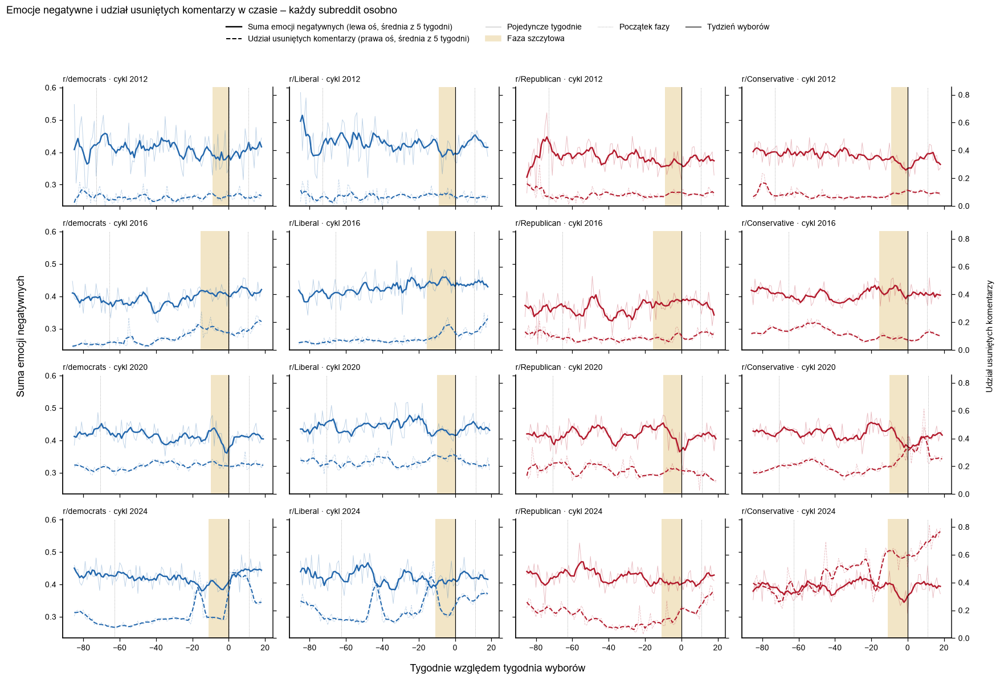

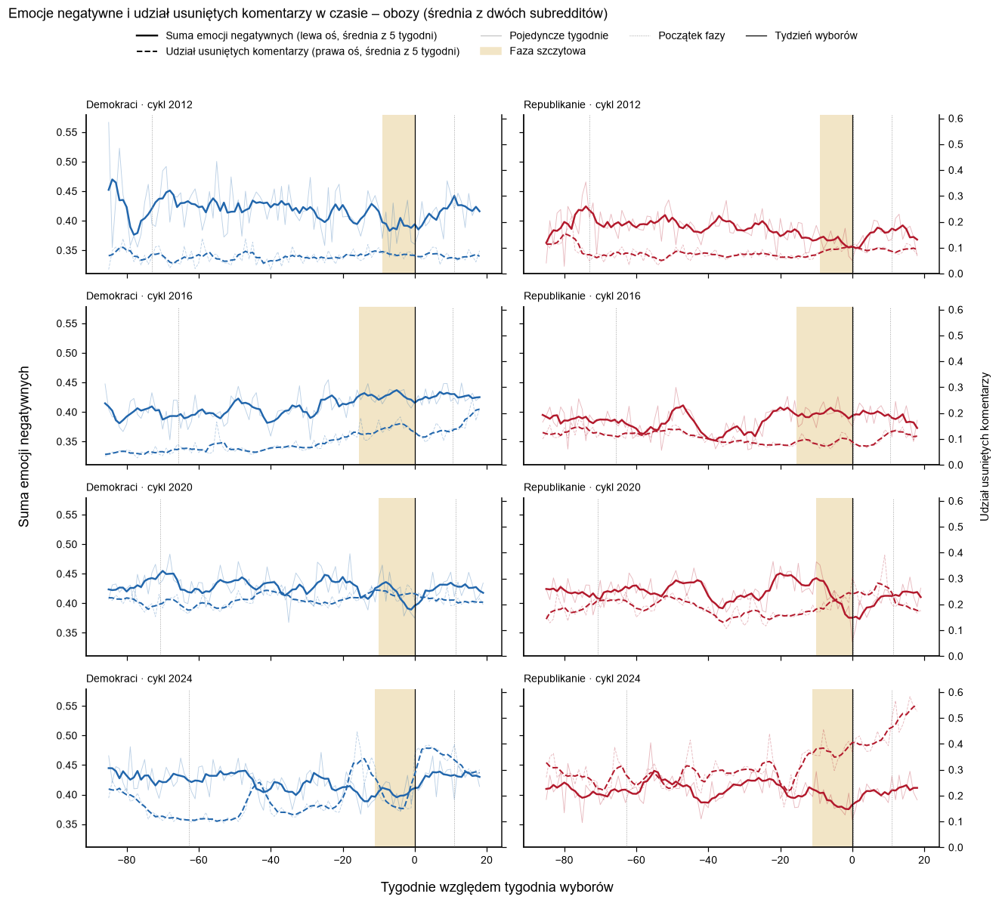

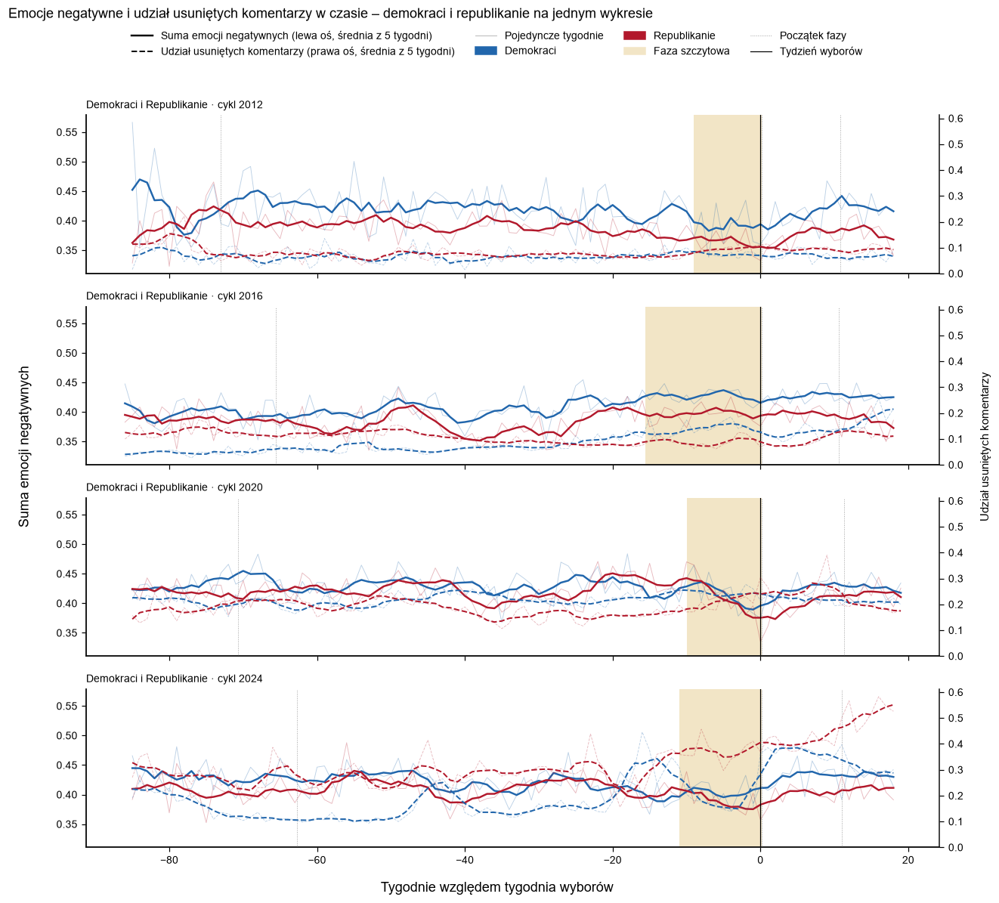

In [6]:
plot_measure(SUBREDDIT_PANELS, "negative", "Emocje negatywne i udział usuniętych komentarzy w czasie – każdy subreddit osobno", second="share_deleted")
plot_measure(CAMP_PANELS, "negative", "Emocje negatywne i udział usuniętych komentarzy w czasie – obozy (średnia z dwóch subredditów)", second="share_deleted")
plot_measure(JOINT_PANEL, "negative", "Emocje negatywne i udział usuniętych komentarzy w czasie – demokraci i republikanie na jednym wykresie", second="share_deleted")

**Jak czytać** (trzy figury: każdy subreddit osobno, obozy osobno, obozy razem)
- Linia ciągła, lewa oś: średnia suma emocji negatywnych w tygodniu (z próby, do 300 komentarzy na tydzień). Linia przerywana, prawa oś: udział usuniętych komentarzy ([deleted] / [removed]) wśród wszystkich rekordów tygodnia z surowych danych. Cienka blada linia to pojedyncze tygodnie, gruba to średnia z 5 tygodni.
- Oś X: tygodnie względem tygodnia wyborów (0). Żółte pole to faza szczytowa, kropkowane linie to początki pozostałych faz. Prawa oś jest wspólna dla całej figury, więc niskie udziały z 2012 wyglądają na płaskie.

**Co widać**
- Poziom emocji negatywnych jest w całym badaniu stały: średnio 0,39–0,43 w każdym cyklu i obozie (demokraci 0,41–0,43, republikanie 0,39–0,42). Wahania tygodniowe to ok. ±0,05, a w obrębie cyklu nie ma wyraźnego trendu.
- W tygodniu wyborów negatywność jest zwykle niższa niż średnia z 8 tygodni wcześniej: w 12 z 16 bloków subreddit × cykl. Obozy razem: 2012 0,346 wobec 0,379, 2020 0,355 wobec 0,408, 2016 0,396 wobec 0,415, 2024 0,386 wobec 0,394. Po wyborach wraca do poziomu sprzed. Przyczyny nie sprawdzaliśmy.
- Udział usuniętych zmienia się między cyklami: 2012 ok. 7–8% (płasko), 2016 rośnie u demokratów z 4,7% w bazie do 13,8% w fazie szczytowej i 17,6% po wyborach, 2020 ok. 20%, 2024 u republikanów z 28% do 37% (szczytowa) i 52% (powyborcza), u demokratów z 16–18% do 37% w fazie przejściowej.
- Skoki udziału usuniętych (np. r/Conservative 2020: 24% w tygodniu −1, 43% w tygodniu wyborów; r/democrats i r/Liberal 2024 w fazie szczytowej) nie mają odpowiednika w emocjach negatywnych. Jedyny wyraźnie współbieżny przebieg to demokraci 2016 (sekcja 11).
- Usunięte komentarze nie mają treści, więc nie znamy ich emocji. Przerywana linia pokazuje tylko, ile ich było.

## 6. Skład emocji negatywnych: gniew, wstręt, strach, smutek

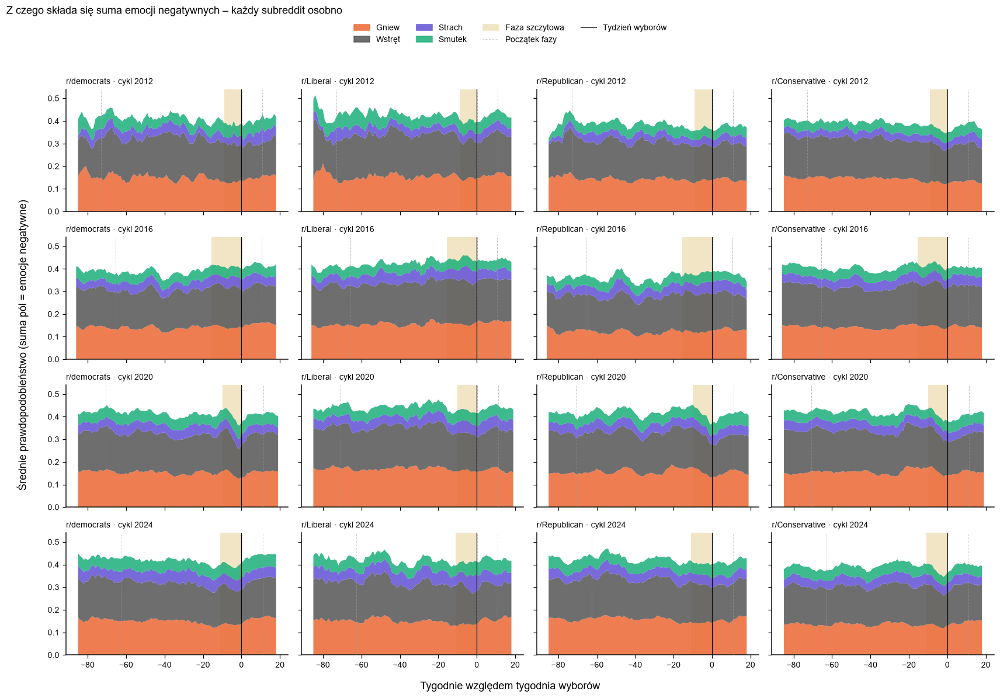

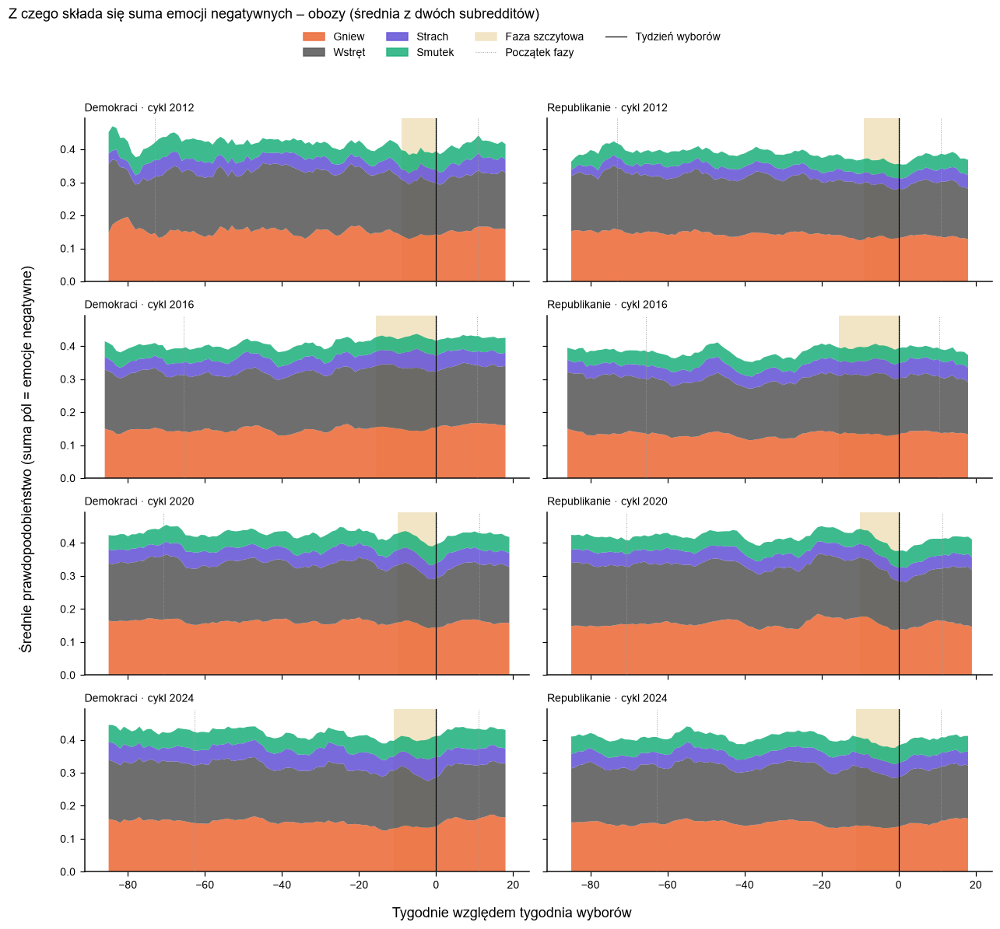

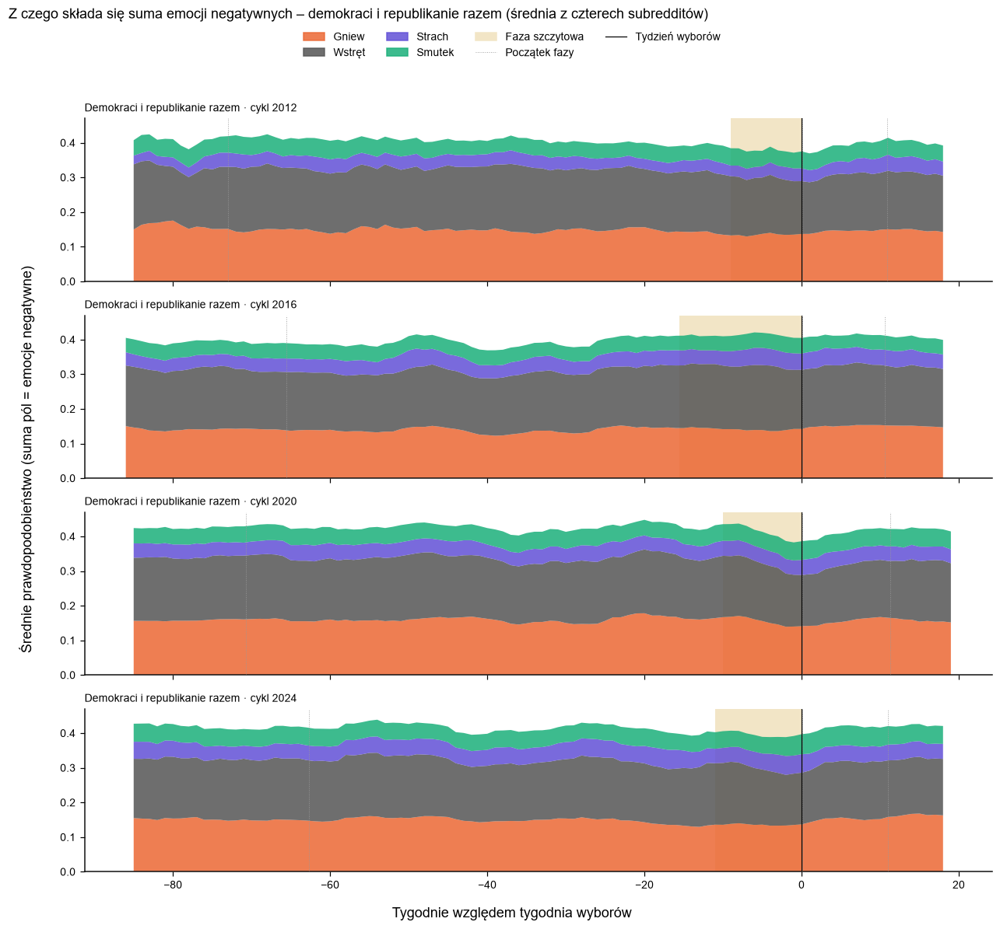

In [7]:
plot_stack(SUBREDDIT_PANELS, NEGATIVE, "Z czego składa się suma emocji negatywnych – każdy subreddit osobno", "Średnie prawdopodobieństwo (suma pól = emocje negatywne)")
plot_stack(CAMP_PANELS, NEGATIVE, "Z czego składa się suma emocji negatywnych – obozy (średnia z dwóch subredditów)", "Średnie prawdopodobieństwo (suma pól = emocje negatywne)")
plot_stack(ALL_PANEL, NEGATIVE, "Z czego składa się suma emocji negatywnych – demokraci i republikanie razem (średnia z czterech subredditów)", "Średnie prawdopodobieństwo (suma pól = emocje negatywne)")

**Jak czytać**
- Wysokość każdego koloru to średnie prawdopodobieństwo danej emocji w tygodniu (średnia z 5 tygodni). Suma wysokości całego słupka to suma emocji negatywnych z poprzedniego wykresu.
- Trzy figury: subreddity osobno, obozy osobno, wszystkie cztery subreddity razem.

**Co widać**
- Największą część sumy stanowi wstręt (ok. 41–43%), potem gniew (36–37%), a strach (ok. 10%) i smutek (11–12%) są małe. Proporcje są niemal takie same u demokratów (36,6 / 41,5 / 10,3 / 11,6%) i republikanów (36,3 / 42,8 / 9,8 / 11,1%).
- W kolejnych cyklach udział strachu rośnie (średnie prawdopodobieństwo 0,035 w 2012, 0,046 w 2024), a gniew jest najwyższy w 2020 (0,158).
- Zmiany sumy w czasie (m.in. spadek w tygodniu wyborów) to głównie zmiany gniewu i wstrętu. Strach i smutek są niemal płaskie.

## 7. Neutralność a emocje negatywne, radość i zaskoczenie

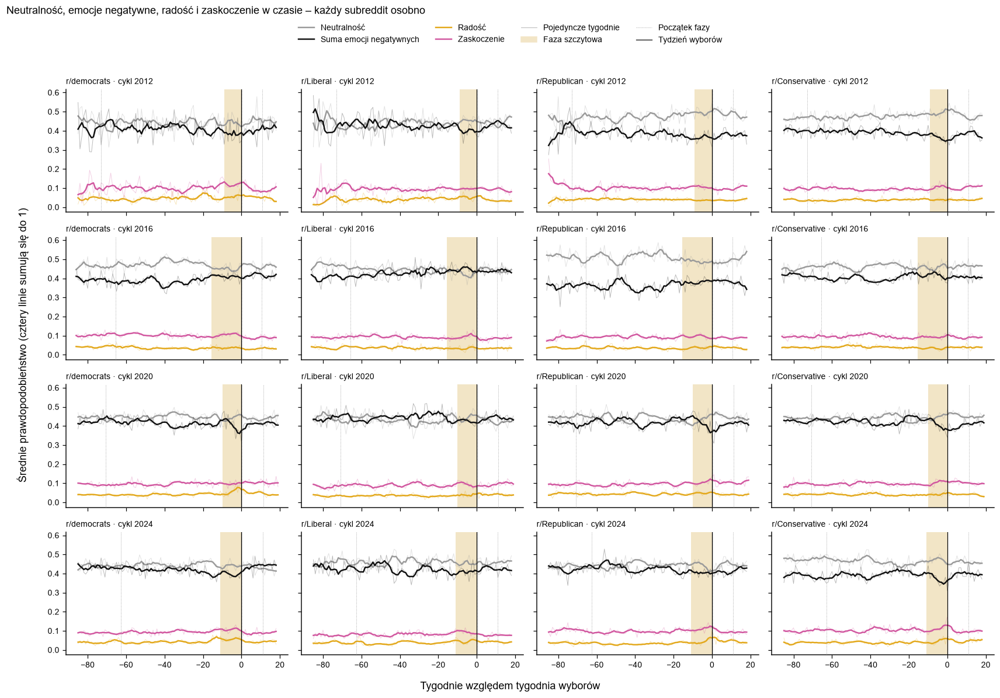

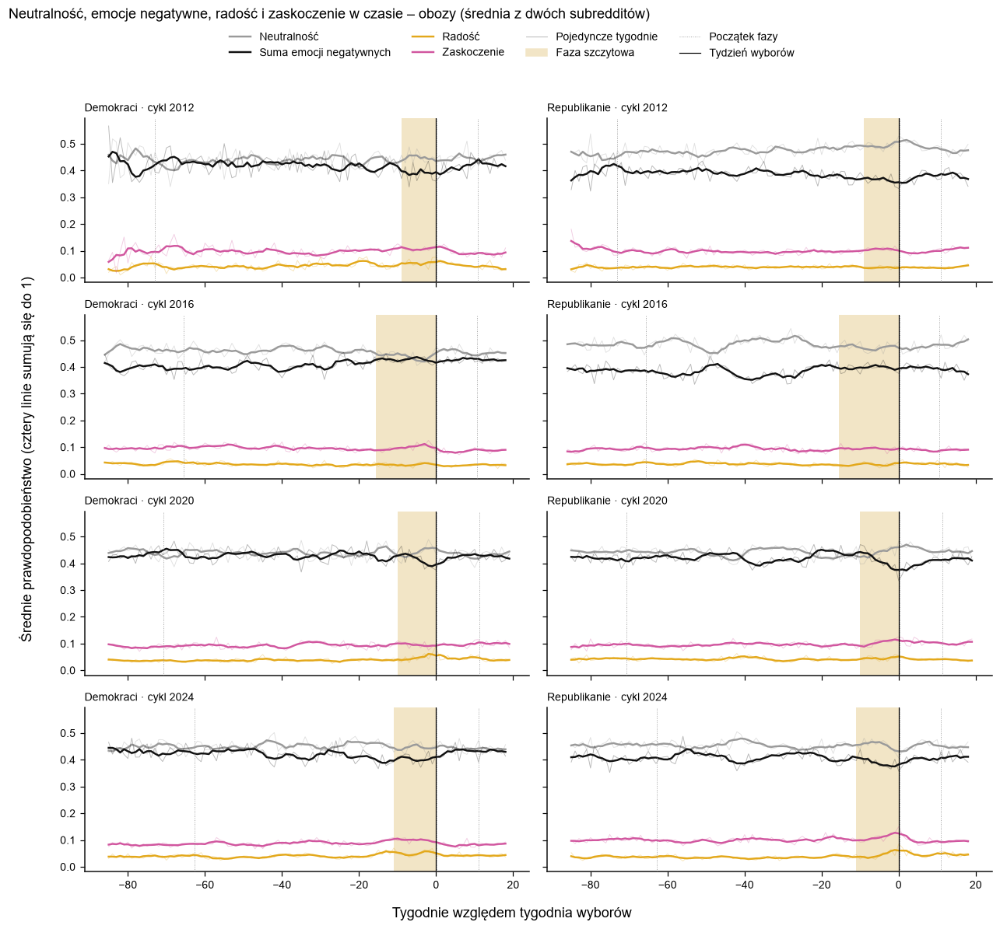

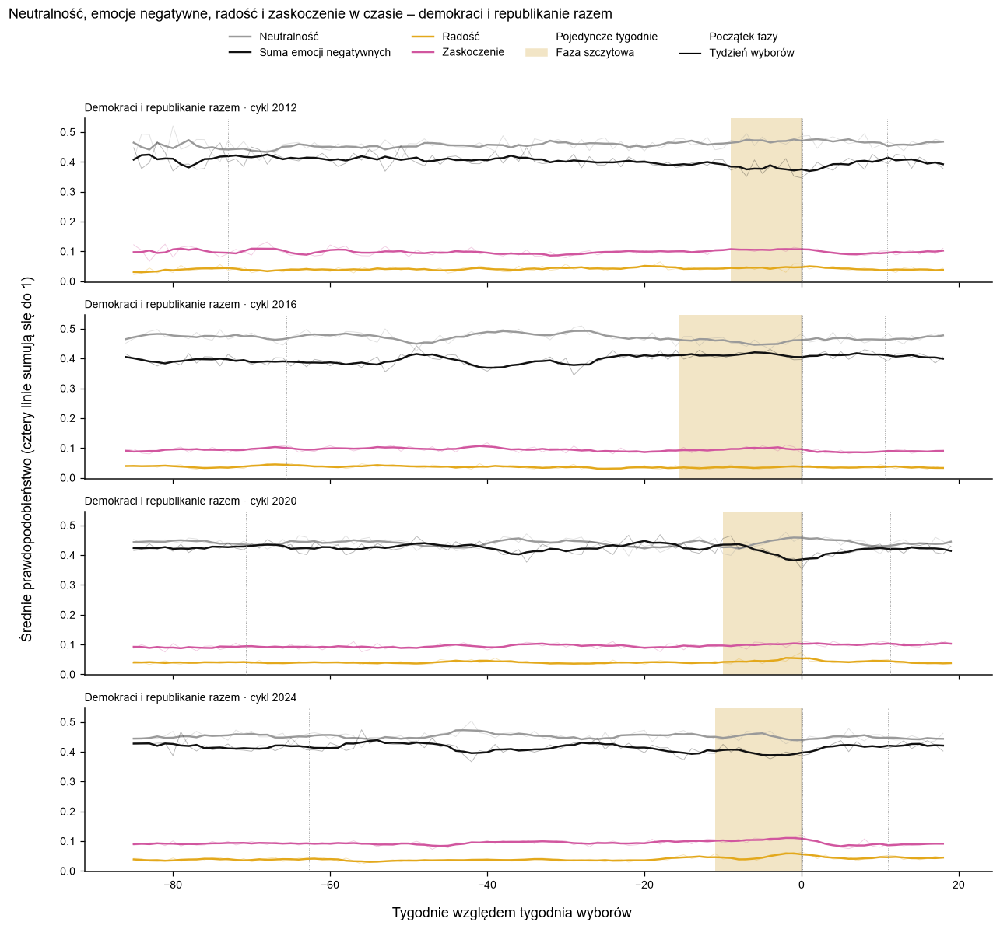

In [8]:
ALL_GROUPS = ["neutral", "negative", "joy", "surprise"]
plot_emotions(SUBREDDIT_PANELS, ALL_GROUPS, "Neutralność, emocje negatywne, radość i zaskoczenie w czasie – każdy subreddit osobno", "Średnie prawdopodobieństwo (cztery linie sumują się do 1)")
plot_emotions(CAMP_PANELS, ALL_GROUPS, "Neutralność, emocje negatywne, radość i zaskoczenie w czasie – obozy (średnia z dwóch subredditów)", "Średnie prawdopodobieństwo (cztery linie sumują się do 1)")
plot_emotions(ALL_PANEL, ALL_GROUPS, "Neutralność, emocje negatywne, radość i zaskoczenie w czasie – demokraci i republikanie razem", "Średnie prawdopodobieństwo (cztery linie sumują się do 1)")

**Jak czytać**
- Cztery linie: neutralność, suma emocji negatywnych, radość i zaskoczenie. Razem dają 1, bo siedem emocji modelu sumuje się do 1 w każdym komentarzu.
- Cienka blada linia to pojedyncze tygodnie, gruba to średnia z 5 tygodni. Trzy figury: subreddity, obozy, obozy razem.

**Co widać**
- Neutralność (0,44–0,48) i emocje negatywne (0,39–0,43) są podobnie wysokie i leżą blisko siebie. Zaskoczenie to ok. 0,09–0,10, a radość tylko ok. 0,04.
- Neutralność i negatywność poruszają się w przeciwnych kierunkach: korelacja tygodniowa wynosi od −0,66 do −0,88 w każdym subreddicie i cyklu. Gdy spada negatywność, rośnie głównie neutralność, a radość i zaskoczenie zmieniają się niewiele.
- Republikanie są nieco bardziej neutralni w 2012 i 2016 (0,475 i 0,484 wobec 0,440 i 0,458 u demokratów). W 2020 i 2024 oba obozy są podobne.
- Średnia neutralność prawie nie zależy od fazy (0,453–0,457).

## 8. Te same wykresy bez neutralności (emocja / (1 − neutralność))

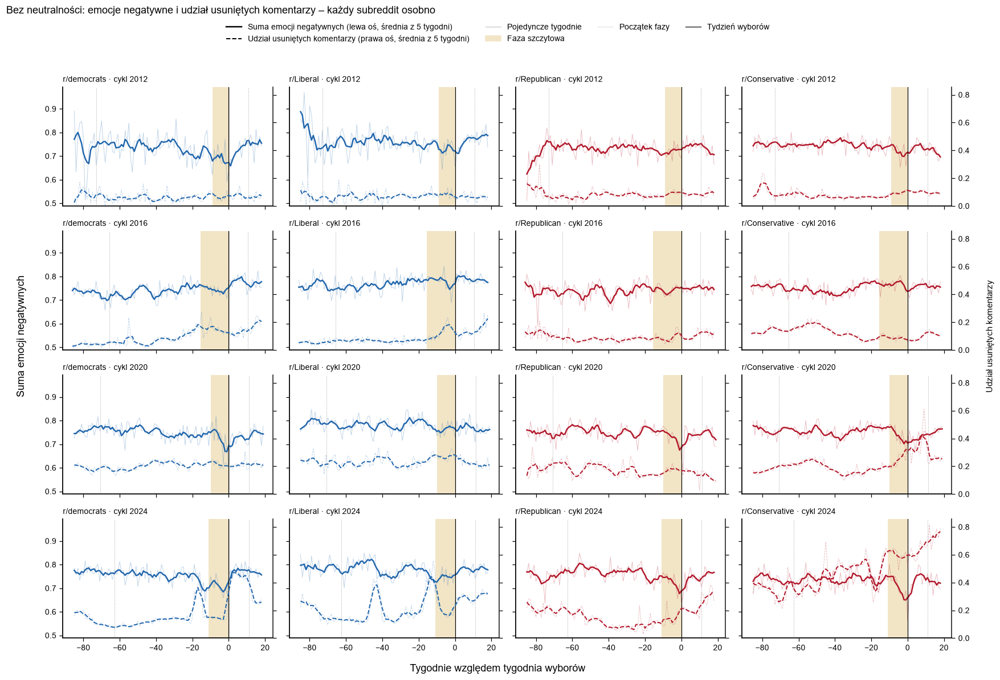

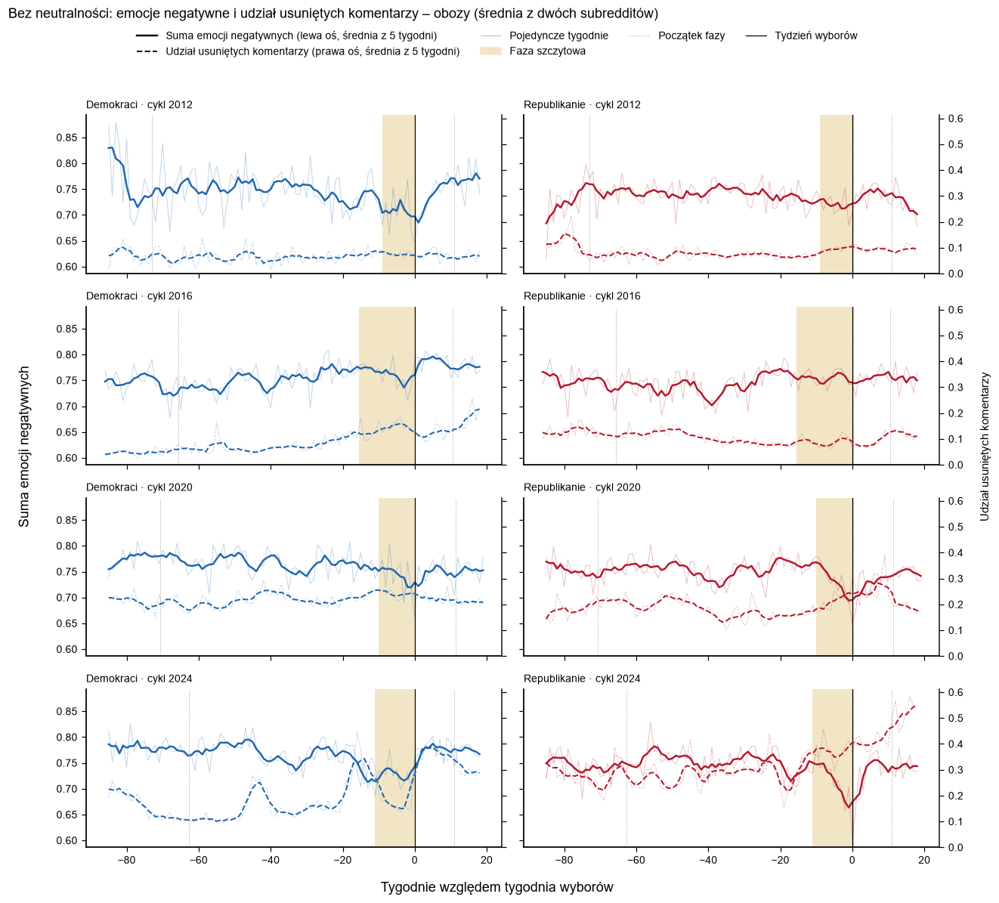

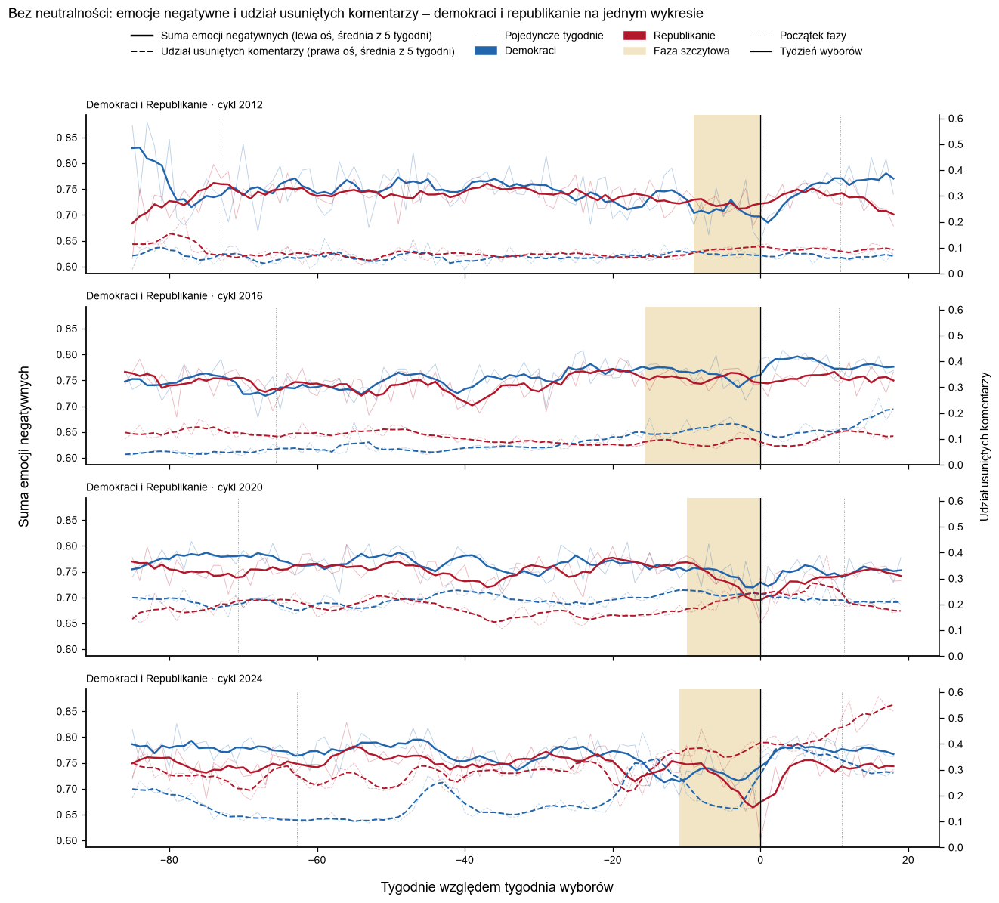

In [9]:
plot_measure(SUBREDDIT_PANELS, "negative_nn", "Bez neutralności: emocje negatywne i udział usuniętych komentarzy – każdy subreddit osobno", second="share_deleted")
plot_measure(CAMP_PANELS, "negative_nn", "Bez neutralności: emocje negatywne i udział usuniętych komentarzy – obozy (średnia z dwóch subredditów)", second="share_deleted")
plot_measure(JOINT_PANEL, "negative_nn", "Bez neutralności: emocje negatywne i udział usuniętych komentarzy – demokraci i republikanie na jednym wykresie", second="share_deleted")

**Jak czytać**
- To samo co w sekcji 5, ale wartość emocji jest podzielona przez (1 − neutralność): pokazuje, jaką część komentarzy niosących jakąkolwiek emocję zajmują emocje negatywne. Neutralność jest więc wyłączona z porównania.
- Linia przerywana na prawej osi to nadal udział usuniętych komentarzy.

**Co widać**
- Bez neutralności emocje negatywne to ok. 0,74–0,77 wszystkich emocji. U demokratów jest to więcej niż u republikanów w każdym cyklu (0,747 / 0,757 / 0,762 / 0,766 wobec 0,736 / 0,747 / 0,749 / 0,744), a u demokratów rośnie z cyklu na cykl.
- Spadek w fazie szczytowej jest wyraźniejszy niż z neutralnością: 0,755 w bazie, 0,738 w szczytowej (z neutralnością 0,411 i 0,404). Neutralność w tym czasie się nie zmienia, więc część różnicy to wzrost radości (0,038 do 0,042) i zaskoczenia (0,094 do 0,101).
- Ogólny kształt przebiegu, w tym obniżenie w okolicy tygodnia wyborów, jest taki sam jak w sekcji 5.

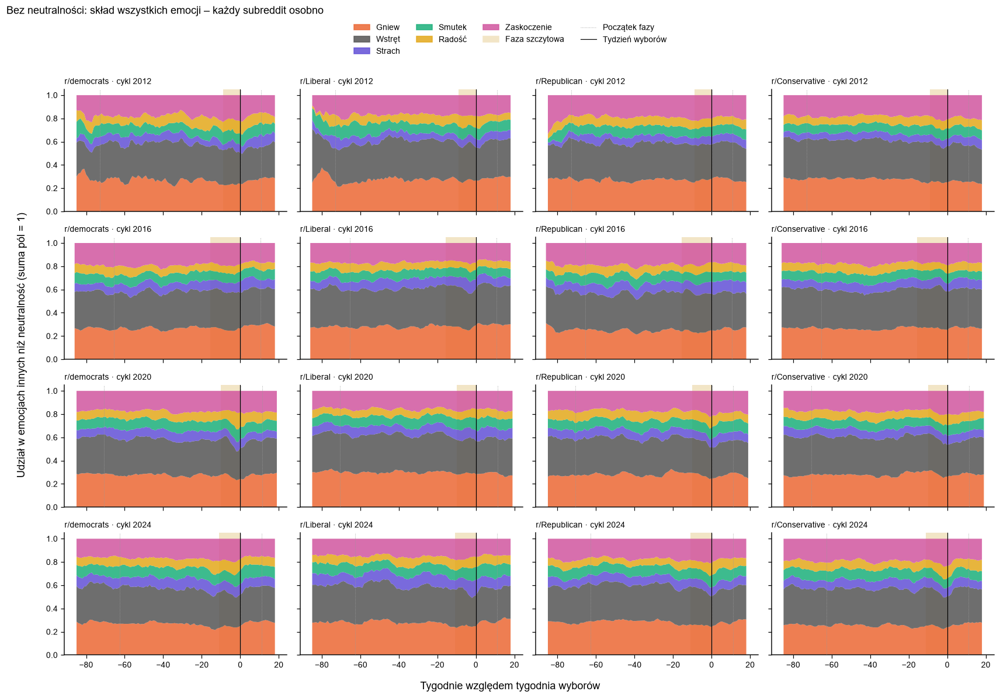

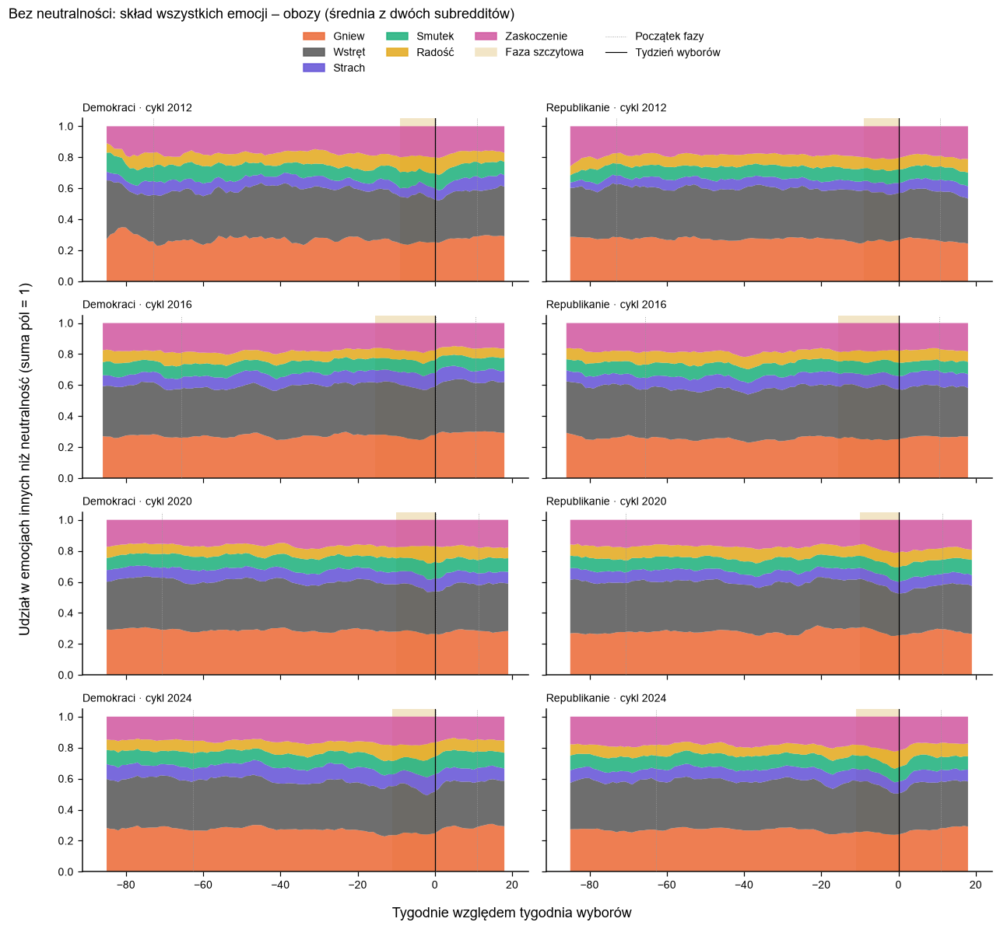

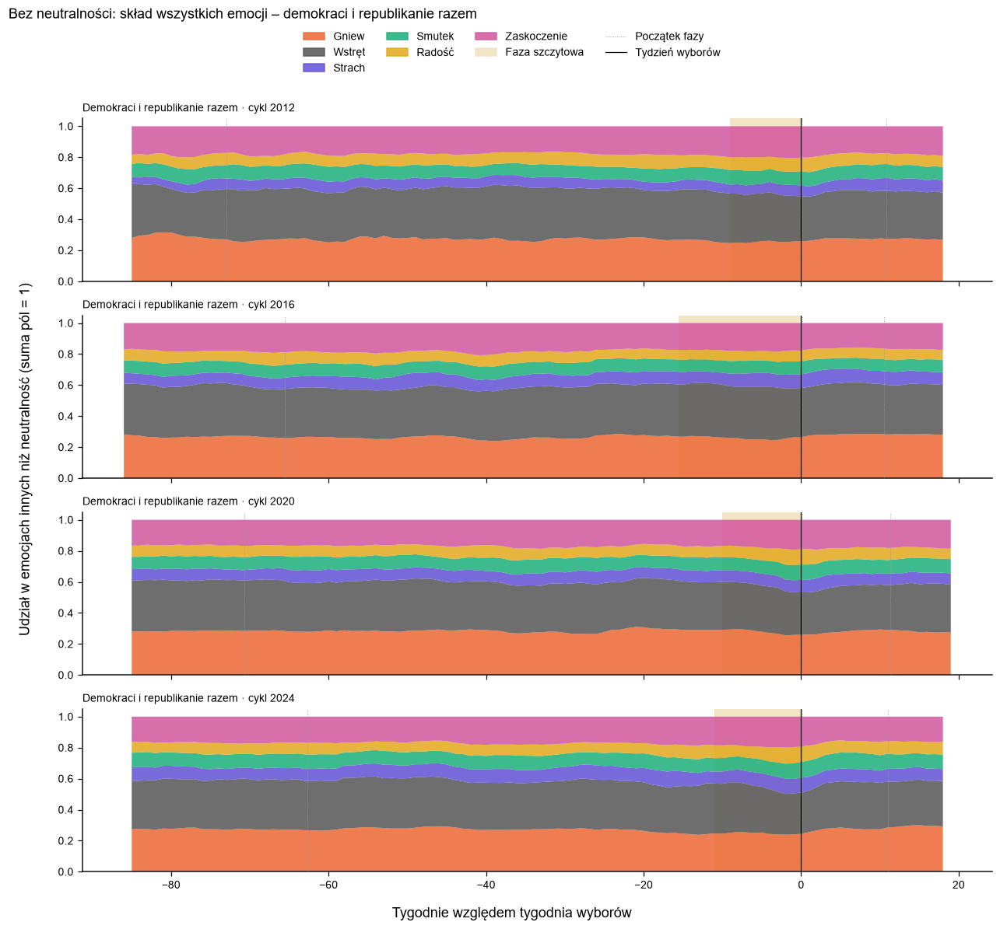

In [10]:
NOT_NEUTRAL_NN = [f"{emotion}_nn" for emotion in NOT_NEUTRAL]
plot_stack(SUBREDDIT_PANELS, NOT_NEUTRAL_NN, "Bez neutralności: skład wszystkich emocji – każdy subreddit osobno", "Udział w emocjach innych niż neutralność (suma pól = 1)")
plot_stack(CAMP_PANELS, NOT_NEUTRAL_NN, "Bez neutralności: skład wszystkich emocji – obozy (średnia z dwóch subredditów)", "Udział w emocjach innych niż neutralność (suma pól = 1)")
plot_stack(ALL_PANEL, NOT_NEUTRAL_NN, "Bez neutralności: skład wszystkich emocji – demokraci i republikanie razem", "Udział w emocjach innych niż neutralność (suma pól = 1)")

**Jak czytać**
- Pola układają sześć emocji (bez neutralności) tak, że w każdym tygodniu sumują się do 1. Wysokość koloru to udział emocji wśród emocji innych niż neutralność (średnia z 5 tygodni).

**Co widać**
- Dominują wstręt (ok. 32%) i gniew (27%), razem prawie 60%. Zaskoczenie to ok. 18%, a strach, smutek i radość mają po 7–9%.
- Podziały są prawie takie same w obu obozach i we wszystkich cyklach. Zmienia się tylko niewielki udział radości i zaskoczenia w czasie.

## 9. Pobudzenie a udział usuniętych komentarzy (H2)

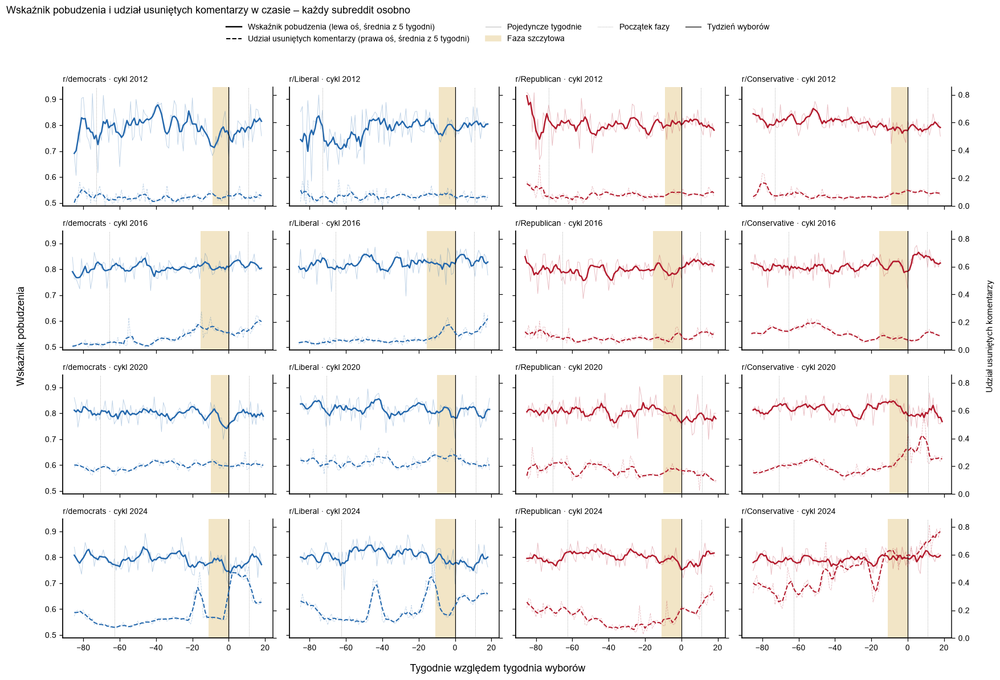

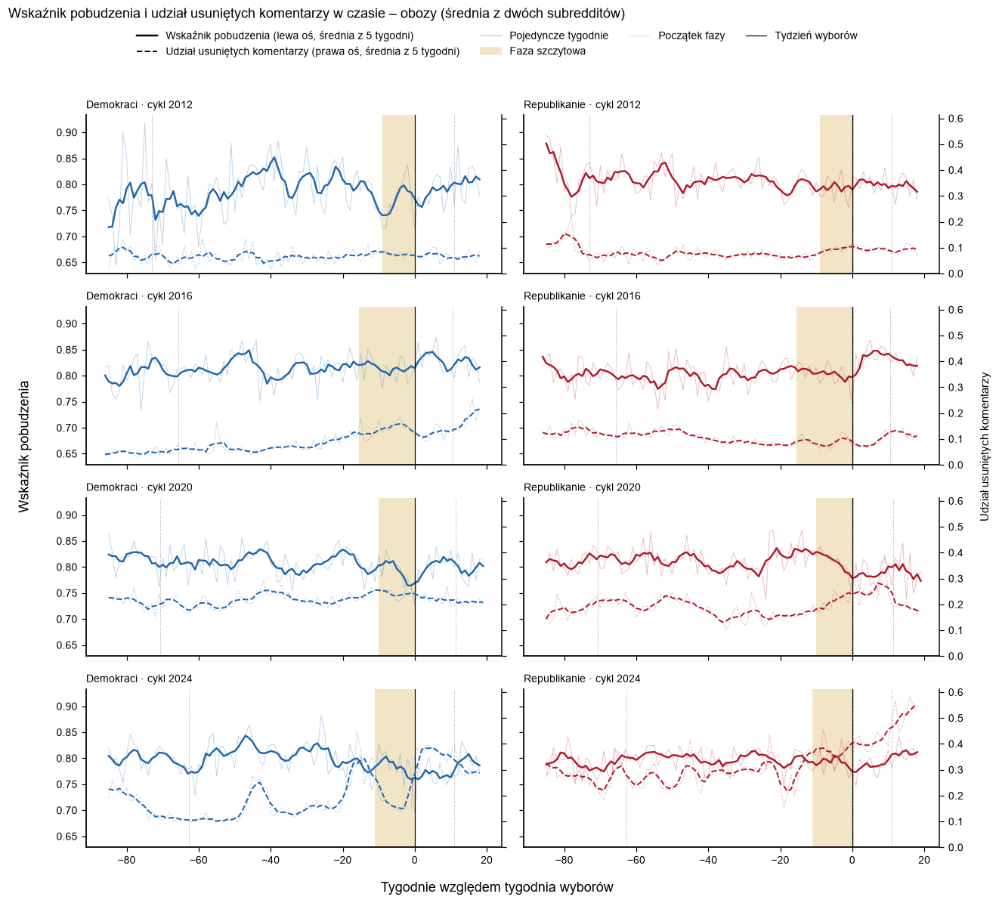

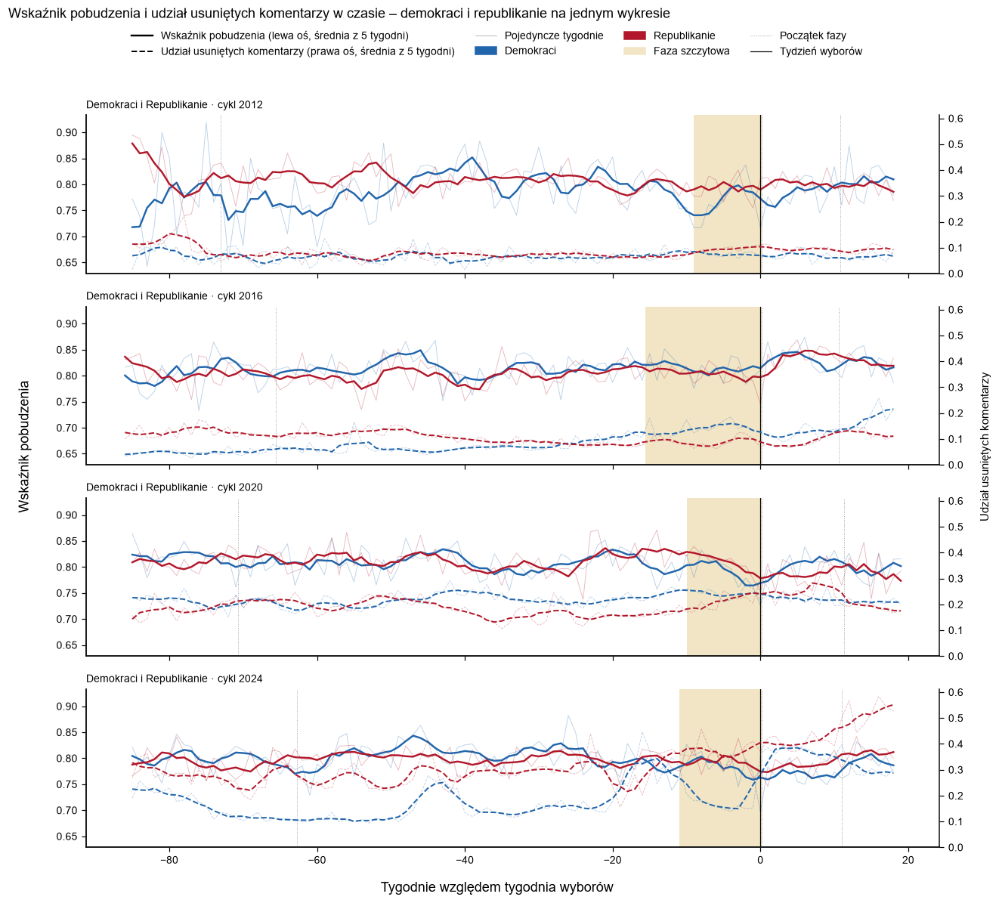

In [11]:
plot_measure(SUBREDDIT_PANELS, "arousal", "Wskaźnik pobudzenia i udział usuniętych komentarzy w czasie – każdy subreddit osobno", second="share_deleted")
plot_measure(CAMP_PANELS, "arousal", "Wskaźnik pobudzenia i udział usuniętych komentarzy w czasie – obozy (średnia z dwóch subredditów)", second="share_deleted")
plot_measure(JOINT_PANEL, "arousal", "Wskaźnik pobudzenia i udział usuniętych komentarzy w czasie – demokraci i republikanie na jednym wykresie", second="share_deleted")

**Jak czytać**
- Wskaźnik pobudzenia to (gniew + strach) / (gniew + strach + smutek), liczony ze średnich tygodniowych. Przyjmuje wartości od 0 do 1, wyżej znaczy więcej gniewu i strachu względem smutku.
- Linia przerywana na prawej osi: udział usuniętych komentarzy.

**Co widać**
- Wskaźnik jest bardzo stały: 0,78–0,82 w każdym cyklu i obozie. Gniew przeważa nad smutkiem mniej więcej trzy do jednego, więc wskaźnik nie ma dużo miejsca na zmiany.
- W fazie szczytowej wskaźnik jest minimalnie niższy niż w bazie: demokraci 0,801 do 0,792, republikanie 0,807 do 0,801. Nie widać wzrostu przed wyborami ani w ich trakcie.
- Udział usuniętych nie wiąże się z pobudzeniem: korelacja tygodniowa dla obozów razem to −0,21 (2012), +0,19 (2016), −0,08 (2020) i −0,26 (2024).

## 10. Emocje negatywne a liczba komentarzy

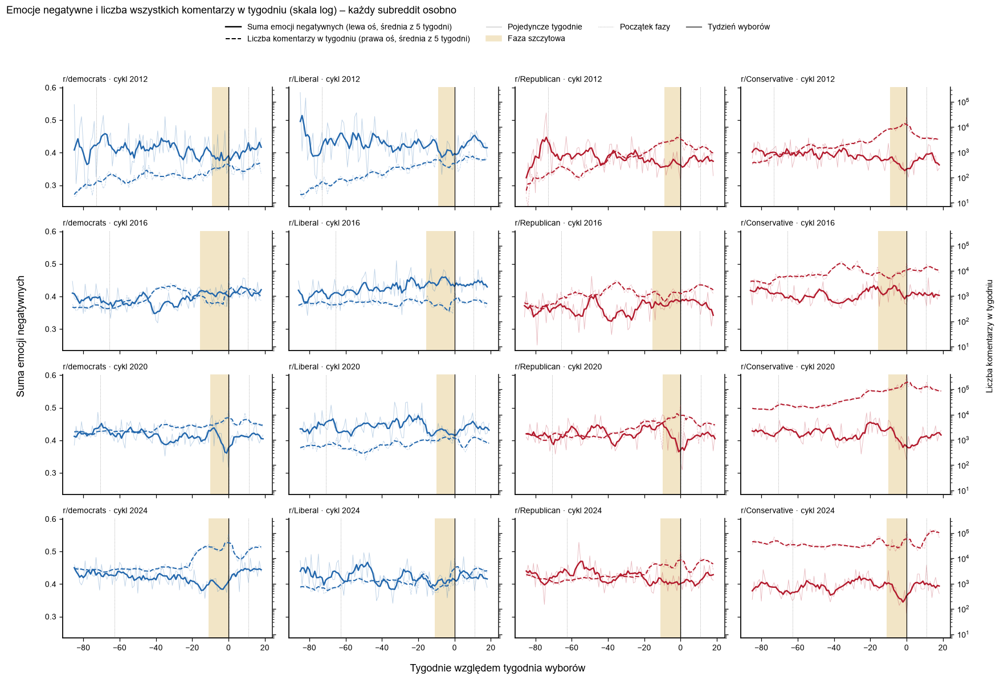

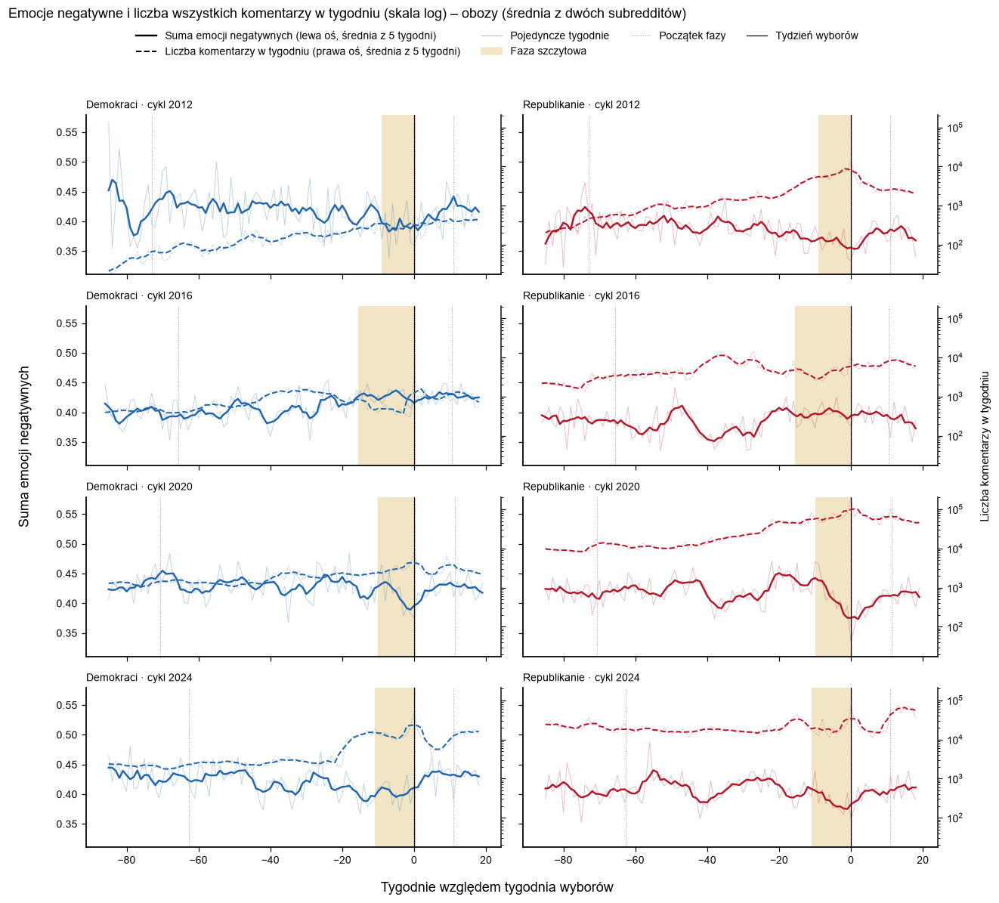

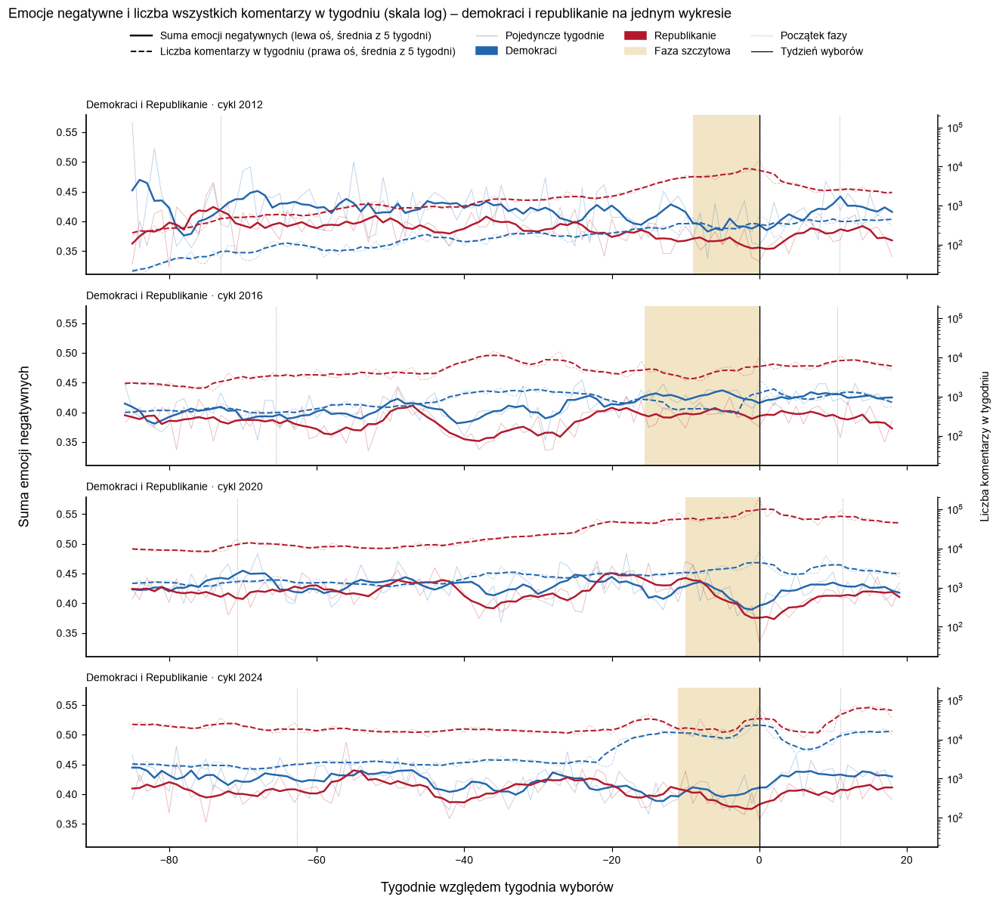

In [12]:
plot_measure(SUBREDDIT_PANELS, "negative", "Emocje negatywne i liczba wszystkich komentarzy w tygodniu (skala log) – każdy subreddit osobno", second="n_raw", second_log=True)
plot_measure(CAMP_PANELS, "negative", "Emocje negatywne i liczba wszystkich komentarzy w tygodniu (skala log) – obozy (średnia z dwóch subredditów)", second="n_raw", second_log=True)
plot_measure(JOINT_PANEL, "negative", "Emocje negatywne i liczba wszystkich komentarzy w tygodniu (skala log) – demokraci i republikanie na jednym wykresie", second="n_raw", second_log=True)

**Jak czytać**
- Linia przerywana na prawej osi to liczba wszystkich komentarzy w tygodniu (w skali logarytmicznej), policzona z surowych danych, razem z usuniętymi. Pokazuje, jak zmienia się ruch w subreddicie.

**Co widać**
- Ruch rośnie o rzędy wielkości: średnio 197 komentarzy na tydzień u demokratów w 2012 wobec 6 385 w 2024, a u republikanów z 2 117 do 22 681 (w 2020: 32 381). W większości plików najwyższy tydzień to tydzień wyborów.
- Emocje negatywne nie rosną razem z ruchem. Korelacja z logarytmem liczby komentarzy jest słabo ujemna albo zerowa: −0,42 (2012), −0,05 (2016), −0,26 (2020) i −0,18 (2024) dla obozów razem.
- W 2012 mały ruch daje bardziej rozrzucone tygodnie (więcej szumu w próbie, sekcja 21).

## 11. Korelacja udziału usuniętych komentarzy z emocjami

In [13]:
CORRELATED = ["negative", "negative_nn", "arousal", "neutral", "anger", "disgust", "fear", "sadness", "joy", "surprise"]
GROUPS = POLITICAL_SUBREDDITS + ["dem", "rep", "all"]
correlations = pd.DataFrame({(group, cycle): cycle_rows(group, cycle)[CORRELATED].corrwith(cycle_rows(group, cycle)["share_deleted"])
                             for group in GROUPS for cycle in CYCLES}).T
correlations.index.names = ["group", "cycle"]
correlations.to_csv(EDA_DIR / "emotions_deleted_correlation.csv")
correlations.round(2)

negative  negative_nn  arousal  neutral  anger  disgust  \
group        cycle                                                            
democrats    2012       0.08         0.09     0.01    -0.04   0.23    -0.09   
             2016       0.35         0.35     0.09    -0.19   0.24     0.19   
             2020      -0.05        -0.01    -0.08     0.08  -0.03    -0.05   
             2024       0.09         0.10    -0.25    -0.02   0.04    -0.18   
Liberal      2012      -0.17        -0.07    -0.06     0.14  -0.26     0.10   
             2016       0.31         0.14     0.10    -0.34   0.18     0.18   
             2020      -0.17         0.01     0.05     0.21  -0.01    -0.19   
             2024      -0.15        -0.11    -0.23     0.13  -0.12    -0.15   
Republican   2012      -0.00        -0.22    -0.07    -0.17   0.15    -0.15   
             2016       0.22         0.23     0.28    -0.14   0.31     0.23   
             2020      -0.05         0.01     0.14     0.09  -0.03     0.02   
             2024       0.17        -0.01    -0.09    -0.29   0.15     0.04   
Conservative 2012      -0.08        -0.15    -0.11     0.00  -0.10    -0.09   
             2016      -0.09        -0.16    -0.16    -0.02  -0.11    -0.05   
             2020      -0.20        -0.24    -0.10     0.10   0.03    -0.40   
             2024       0.13         0.01     0.26    -0.19   0.26    -0.00   
dem          2012      -0.12         0.01    -0.14     0.17  -0.07    -0.10   
             2016       0.47         0.35     0.13    -0.37   0.30     0.33   
             2020      -0.11        -0.04    -0.07     0.11   0.01    -0.17   
             2024      -0.06        -0.07    -0.35     0.03  -0.04    -0.30   
rep          2012      -0.06        -0.23    -0.15    -0.09   0.09    -0.24   
             2016       0.09         0.04     0.06    -0.10   0.17     0.11   
             2020      -0.22        -0.23    -0.01     0.13  -0.06    -0.33   
             2024       0.03        -0.05     0.09    -0.12   0.21    -0.11   
all          2012      -0.20        -0.08    -0.21     0.20   0.03    -0.32   
             2016       0.36         0.26     0.19    -0.32   0.29     0.23   
             2020      -0.12        -0.23    -0.08    -0.03  -0.02    -0.27   
             2024      -0.07        -0.19    -0.26    -0.12   0.06    -0.35   

                    fear  sadness   joy  surprise  
group        cycle                                 
democrats    2012  -0.06     0.07 -0.06     -0.04  
             2016   0.19     0.10 -0.20     -0.20  
             2020  -0.06     0.06  0.03     -0.04  
             2024   0.12     0.36 -0.01     -0.14  
Liberal      2012  -0.04    -0.09  0.05      0.03  
             2016   0.19     0.04 -0.07      0.05  
             2020  -0.07    -0.07  0.03     -0.13  
             2024  -0.08     0.18  0.11      0.01  
Republican   2012  -0.16     0.18 -0.06      0.32  
             2016  -0.07    -0.19  0.00     -0.22  
             2020   0.01    -0.18  0.08     -0.11  
             2024   0.05     0.19  0.20     -0.03  
Conservative 2012   0.04     0.10  0.01      0.16  
             2016  -0.08     0.13  0.18      0.07  
             2020   0.01     0.15  0.08      0.19  
             2024   0.09    -0.12  0.19     -0.07  
dem          2012  -0.10     0.07 -0.02     -0.04  
             2016   0.19     0.09 -0.19     -0.15  
             2020  -0.07     0.06  0.14     -0.12  
             2024   0.06     0.39  0.20     -0.08  
rep          2012  -0.07     0.23 -0.01      0.29  
             2016  -0.17    -0.04  0.02     -0.02  
             2020   0.12     0.03  0.01      0.24  
             2024  -0.05     0.01  0.31     -0.14  
all          2012  -0.18     0.19 -0.02      0.03  
             2016   0.19    -0.00 -0.13     -0.09  
             2020   0.14     0.13  0.36      0.07  
             2024   0.05     0.38  0.46     -0.04

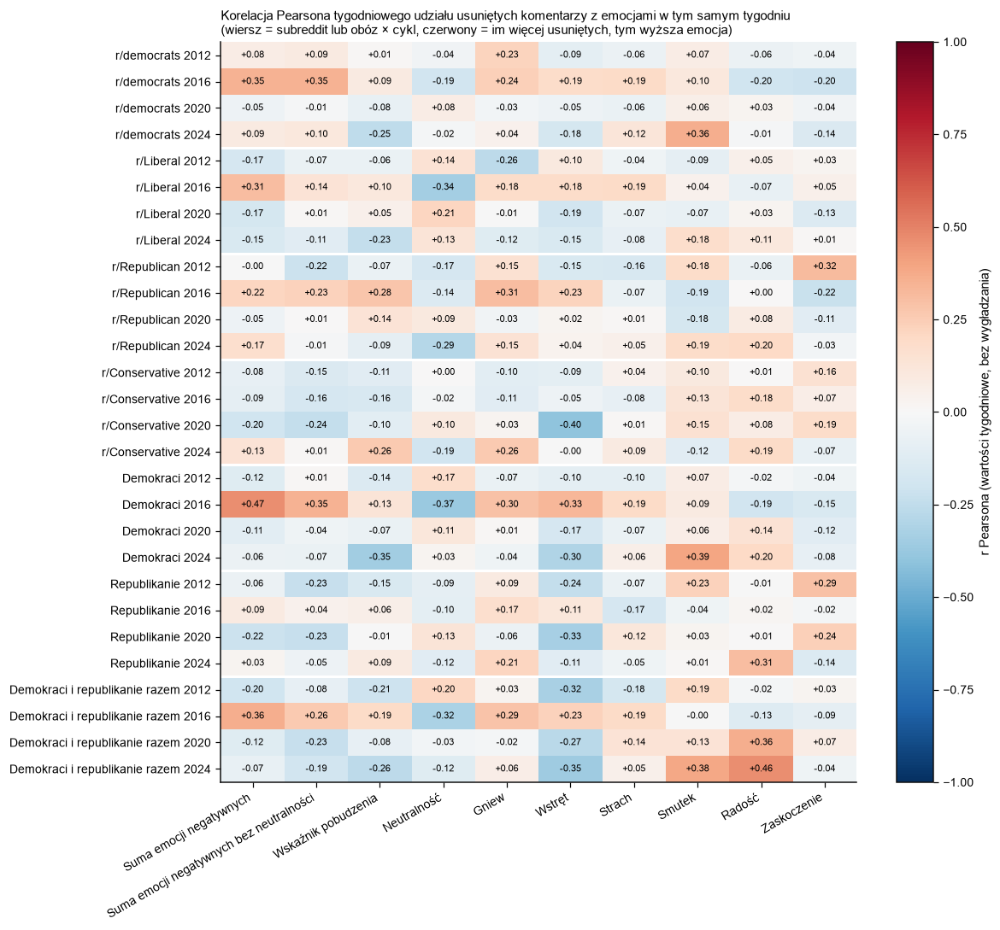

In [14]:
values = correlations.to_numpy()
fig, ax = plt.subplots(figsize=(11, 10))
image = ax.imshow(values, cmap="RdBu_r", vmin=-1, vmax=1, aspect="auto")
ax.set_xticks(range(len(CORRELATED)), [label_of(column) + (" bez neutralności" if column.endswith("_nn") else "") for column in CORRELATED],
              rotation=30, ha="right")
ax.set_yticks(range(len(correlations)), [f"{GROUP_LABELS[group]} {cycle}" for group, cycle in correlations.index])
for row in range(values.shape[0]):
    for column in range(values.shape[1]):
        ax.text(column, row, f"{values[row, column]:+.2f}", ha="center", va="center", fontsize=7,
                color="white" if abs(values[row, column]) > 0.6 else "black")
for boundary in range(len(CYCLES), len(correlations), len(CYCLES)):
    ax.axhline(boundary - 0.5, color="white", linewidth=2)
ax.set_title("Korelacja Pearsona tygodniowego udziału usuniętych komentarzy z emocjami w tym samym tygodniu\n"
             "(wiersz = subreddit lub obóz × cykl, czerwony = im więcej usuniętych, tym wyższa emocja)", loc="left")
fig.colorbar(image, ax=ax, label="r Pearsona (wartości tygodniowe, bez wygładzania)")
plt.tight_layout()
plt.show()

**Jak czytać**
- Wiersz to subreddit, obóz albo oba obozy razem w danym cyklu (ok. 104–105 tygodni). Liczba w komórce to korelacja Pearsona między tygodniowym udziałem usuniętych komentarzy a daną miarą w tym samym tygodniu, bez wygładzania.
- Czerwony: im więcej usuniętych, tym wyższa miara. Niebieski: im więcej usuniętych, tym niższa. Kolejne tygodnie nie są niezależne, a przy ok. 100 tygodniach wartości do ±0,2 nie odróżniają się od przypadku.

**Co widać**
- Korelacje są słabe i bez stałego znaku. Średnia dla sumy emocji negatywnych: −0,08 (2012), +0,24 (2016), −0,13 (2020), +0,02 (2024).
- Jedyny wyraźny związek dla emocji negatywnych to demokraci w 2016: r = +0,47 (r/democrats +0,35, r/Liberal +0,31), a dla obozów razem +0,36. W 2020 republikanie mają −0,22.
- W 2024 (obozy razem): smutek +0,38, radość +0,46, wstręt −0,35. W 2020 radość +0,36, wstręt −0,27. Te wartości nie powtarzają się w innych cyklach.
- Wstręt koreluje ujemnie z udziałem usuniętych w prawie każdym cyklu obozów razem (−0,32, +0,23, −0,27, −0,35), z jednym wyjątkiem w 2016.

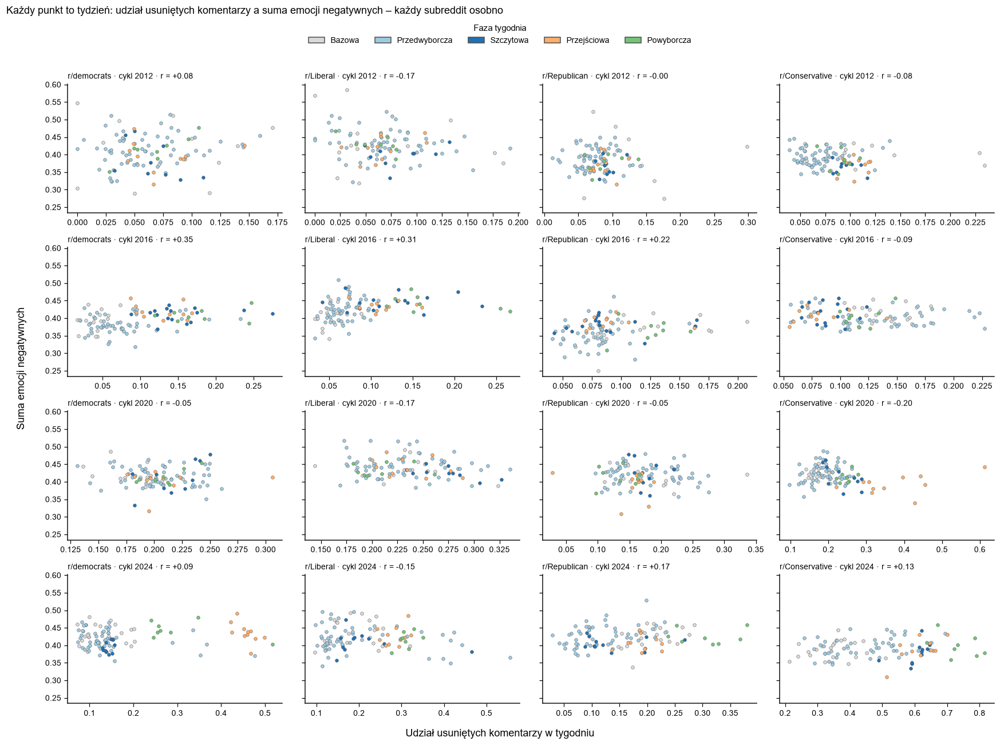

In [15]:
def plot_scatter(panels, measure, title):
    """Tygodnie jako punkty: udział usuniętych (oś X) i miara emocji (oś Y), kolor = faza."""
    fig, axes = plt.subplots(len(CYCLES), len(panels), figsize=(4 * len(panels), 12), sharey=True, squeeze=False)
    for row, cycle in enumerate(CYCLES):
        for column, groups in enumerate(panels):
            rows = cycle_rows(groups[0], cycle)
            for phase in PHASE_ORDER:
                in_phase = rows[rows["phase"] == phase]
                axes[row, column].scatter(in_phase["share_deleted"], in_phase[measure], color=PHASE_COLORS[phase], s=14,
                                          edgecolor="0.3", linewidth=0.3)
            axes[row, column].set_title(f"{GROUP_LABELS[groups[0]]} · cykl {cycle} · r = {correlations.loc[(groups[0], cycle), measure]:+.2f}",
                                        loc="left", fontsize=9)
    handles = [Patch(facecolor=PHASE_COLORS[phase], edgecolor="0.3", label=PHASE_LABELS[phase]) for phase in PHASE_ORDER]
    fig.suptitle(title, x=0.01, ha="left", fontsize=12)
    fig.legend(handles=handles, loc="upper center", bbox_to_anchor=(0.5, 0.965), ncol=len(handles), title="Faza tygodnia")
    fig.supxlabel("Udział usuniętych komentarzy w tygodniu")
    fig.supylabel(label_of(measure))
    plt.tight_layout(rect=(0.02, 0, 1, 0.93))
    plt.show()


plot_scatter(SUBREDDIT_PANELS, "negative", "Każdy punkt to tydzień: udział usuniętych komentarzy a suma emocji negatywnych – każdy subreddit osobno")

**Jak czytać**
- Każdy punkt to jeden tydzień. Oś X: udział usuniętych komentarzy, oś Y: suma emocji negatywnych. Kolor punktu to faza cyklu. W tytule panelu jest ta sama korelacja co na mapie.

**Co widać**
- Większość paneli to chmury bez wyraźnego nachylenia. Wyjątek to r/democrats i r/Liberal w 2016 (r = +0,35 i +0,31): tygodnie z wyższym udziałem usuniętych (fazy szczytowa, przejściowa i powyborcza) mają wyższą negatywność.
- Udział usuniętych różni się głównie między fazami, a nie w obrębie jednej fazy. W 2024 punkty r/democrats i r/Liberal rozdzielają się na dwie grupy (niski udział w fazach wcześniejszych, wysoki w przejściowej i powyborczej) przy podobnej negatywności.
- W r/Conservative 2020 osiem z dziewięciu tygodni z udziałem usuniętych powyżej 0,3 ma negatywność poniżej średniej bloku (0,419), co daje r = −0,20.

## 12. Korelacja z przesunięciem w czasie

In [16]:
LAGS = range(-4, 5)
lag_rows = []
for group in GROUPS:
    for cycle in CYCLES:
        rows = cycle_rows(group, cycle).set_index("week")
        rows = rows.reindex(range(rows.index.min(), rows.index.max() + 1))  # brakujący tydzień nie może przesunąć szeregu
        for lag in LAGS:
            lag_rows.append({"group": group, "cycle": cycle, "lag": lag,
                             "r": rows["negative"].corr(rows["share_deleted"].shift(lag))})
lagged = pd.DataFrame(lag_rows)
lagged.to_csv(EDA_DIR / "emotions_deleted_lagged_correlation.csv", index=False)
lagged.pivot_table(index=["group", "cycle"], columns="lag", values="r", sort=False).round(2)

lag                   -4    -3    -2    -1     0     1     2     3     4
group        cycle                                                      
democrats    2012  -0.13  0.19 -0.12 -0.07  0.08 -0.04 -0.05 -0.16 -0.14
             2016   0.17  0.21  0.30  0.22  0.35  0.33  0.36  0.41  0.39
             2020  -0.08 -0.15 -0.21 -0.09 -0.05 -0.11 -0.10 -0.22 -0.36
             2024  -0.07  0.01  0.05  0.06  0.09  0.12  0.10  0.10  0.17
Liberal      2012   0.01 -0.15  0.03  0.13 -0.17  0.19  0.12  0.01  0.01
             2016   0.30  0.35  0.34  0.28  0.31  0.21  0.24  0.18  0.23
             2020  -0.02 -0.18 -0.10 -0.22 -0.17 -0.10 -0.15 -0.12 -0.18
             2024   0.07  0.11  0.10 -0.08 -0.15 -0.19 -0.16 -0.18 -0.15
Republican   2012  -0.13 -0.04 -0.33 -0.15 -0.00 -0.09 -0.02  0.10  0.20
             2016   0.02 -0.01  0.12  0.04  0.22 -0.05  0.01  0.13  0.04
             2020  -0.01 -0.09 -0.13  0.10 -0.05  0.01 -0.04 -0.05 -0.07
             2024  -0.11 -0.10  0.00  0.05  0.17  0.09  0.13  0.01  0.12
Conservative 2012  -0.03  0.03 -0.03 -0.04 -0.08 -0.19 -0.09 -0.00 -0.05
             2016  -0.05 -0.07 -0.14 -0.09 -0.09 -0.17 -0.20 -0.17 -0.16
             2020  -0.33 -0.23 -0.27 -0.32 -0.20 -0.15 -0.21 -0.25 -0.25
             2024  -0.00 -0.02 -0.02  0.11  0.13  0.12  0.04 -0.01  0.04
dem          2012   0.02  0.05  0.01  0.02 -0.12  0.03 -0.07 -0.19 -0.07
             2016   0.40  0.48  0.44  0.42  0.47  0.45  0.48  0.48  0.52
             2020  -0.01 -0.14 -0.09 -0.17 -0.11 -0.07 -0.24 -0.09 -0.25
             2024  -0.08  0.00  0.04 -0.04 -0.06 -0.04 -0.02 -0.04 -0.00
rep          2012  -0.13 -0.02 -0.22 -0.17 -0.06 -0.08 -0.10  0.06  0.22
             2016  -0.01 -0.07  0.03 -0.02  0.09 -0.15 -0.15 -0.06 -0.11
             2020  -0.21 -0.23 -0.24 -0.16 -0.22 -0.12 -0.14 -0.22 -0.21
             2024  -0.25 -0.22 -0.14 -0.06  0.03 -0.01 -0.07 -0.19 -0.12
all          2012   0.01  0.05 -0.03 -0.18 -0.20 -0.18 -0.15 -0.16 -0.03
             2016   0.31  0.37  0.38  0.34  0.36  0.27  0.24  0.32  0.33
             2020  -0.06 -0.22 -0.21 -0.18 -0.12 -0.04 -0.25 -0.26 -0.31
             2024  -0.20 -0.14 -0.06 -0.07 -0.07 -0.04 -0.09 -0.14 -0.07

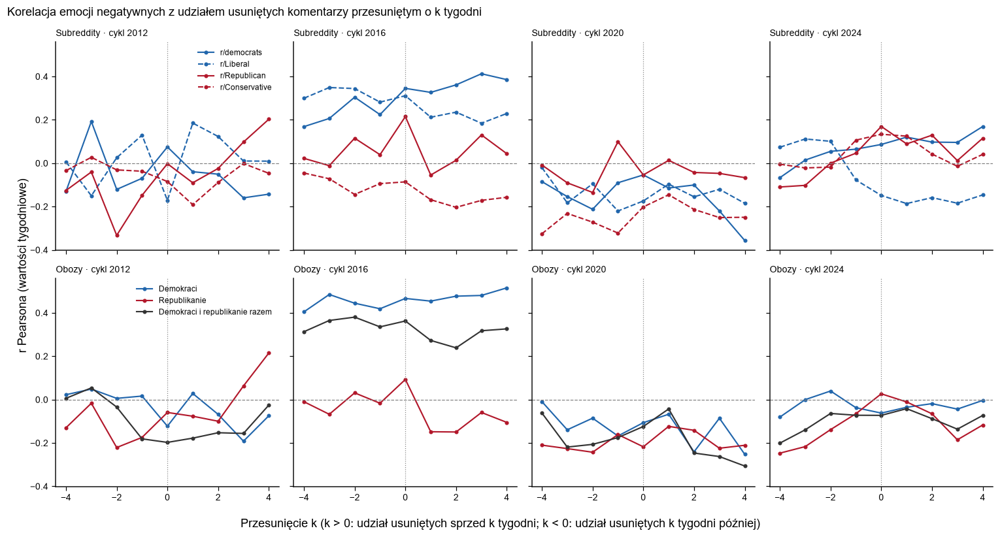

In [17]:
LAG_STYLES = {"democrats": "-", "Liberal": "--", "Republican": "-", "Conservative": "--", "dem": "-", "rep": "-", "all": "-"}
fig, axes = plt.subplots(2, len(CYCLES), figsize=(14, 7.5), sharex=True, sharey=True)
for row, groups in enumerate([POLITICAL_SUBREDDITS, ["dem", "rep", "all"]]):
    for column, cycle in enumerate(CYCLES):
        for group in groups:
            rows = lagged[(lagged["group"] == group) & (lagged["cycle"] == cycle)]
            axes[row, column].plot(rows["lag"], rows["r"], color=GROUP_COLORS[group], linestyle=LAG_STYLES[group], marker="o",
                                   markersize=3, linewidth=1.4, label=GROUP_LABELS[group])
        axes[row, column].axhline(0, color="0.5", linewidth=0.8, linestyle="--")
        axes[row, column].axvline(0, color="0.5", linewidth=0.8, linestyle=":")
        axes[row, column].set_title(f"{'Subreddity' if row == 0 else 'Obozy'} · cykl {cycle}", loc="left", fontsize=9)
    axes[row, 0].legend(fontsize=8)
fig.suptitle("Korelacja emocji negatywnych z udziałem usuniętych komentarzy przesuniętym o k tygodni", x=0.01, ha="left", fontsize=12)
fig.supxlabel("Przesunięcie k (k > 0: udział usuniętych sprzed k tygodni; k < 0: udział usuniętych k tygodni później)")
fig.supylabel("r Pearsona (wartości tygodniowe)")
plt.tight_layout()
plt.show()

**Jak czytać**
- Oś X: przesunięcie k w tygodniach. Dla k > 0 negatywność w tygodniu t porównujemy z udziałem usuniętych sprzed k tygodni, dla k < 0 z udziałem k tygodni późniejszym. k = 0 to ta sama korelacja co na mapie.
- Górny wiersz: subreddity, dolny: obozy (i oba razem). Linia pozioma to r = 0.

**Co widać**
- Nie ma jednego przesunięcia, które byłoby najlepsze we wszystkich cyklach. Dla obozów razem największa korelacja wypada przy k = 0 (2012, r = −0,20), k = −2 (2016, +0,38), k = +4 (2020, −0,31) i k = −4 (2024, −0,20).
- Krzywe są prawie płaskie: w 2016 demokraci mają r ok. +0,4–0,5 przy każdym k od −4 do +4. To zgodne ze wspólnym wolnym trendem obu szeregów, a nie z reakcją z opóźnieniem, bo sąsiednie tygodnie niosą prawie tę samą informację.
- Nie ma więc sygnału, że usunięcia poprzedzają wzrost negatywności ani że za nim podążają.

## 13. Emocje komentarzy usuniętych później przez moderację (cykl 2024)

In [18]:
removed_parts = []
for subreddit in POLITICAL_SUBREDDITS:
    emotions = pd.read_parquet(PROCESSED_DIR / "emotions" / f"{subreddit}_2024_emotions.parquet")
    clean = pd.read_parquet(PROCESSED_DIR / "clean" / f"r_{subreddit}_comments_2024.parquet", columns=["id", "removed_later"])
    removed_parts.append(emotions.merge(clean, on="id").assign(subreddit=subreddit))
removed = pd.concat(removed_parts, ignore_index=True)
removed["negative"] = removed[NEGATIVE].sum(axis=1)
removed = pd.concat([removed.assign(group=removed["subreddit"]), removed.assign(group=removed["subreddit"].map(SUBREDDITS)),
                     removed.assign(group="all")], ignore_index=True)
removed_means = removed.groupby(["group", "removed_later"])[EMOTIONS + ["negative"]].mean().reindex(GROUPS, level="group")
removed_counts = removed.groupby(["group", "removed_later"]).size().unstack().reindex(GROUPS)
removed_means.to_csv(EDA_DIR / "emotions_removed_later.csv")
removed_means.assign(n=removed_counts.stack()).round(3)

anger  disgust   fear    joy  neutral  sadness  \
group        removed_later                                                   
democrats    False          0.151    0.169  0.048  0.044    0.443    0.053   
             True           0.163    0.195  0.053  0.038    0.400    0.059   
Liberal      False          0.151    0.168  0.052  0.039    0.459    0.049   
             True           0.183    0.181  0.048  0.031    0.416    0.061   
Republican   False          0.156    0.171  0.042  0.037    0.446    0.050   
             True           0.178    0.187  0.047  0.037    0.401    0.049   
Conservative False          0.136    0.166  0.041  0.040    0.467    0.046   
             True           0.153    0.179  0.042  0.044    0.434    0.049   
dem          False          0.151    0.168  0.050  0.041    0.451    0.051   
             True           0.171    0.189  0.051  0.035    0.407    0.060   
rep          False          0.146    0.169  0.042  0.039    0.456    0.048   
             True           0.167    0.184  0.045  0.040    0.416    0.049   
all          False          0.148    0.169  0.046  0.040    0.454    0.049   
             True           0.169    0.186  0.047  0.038    0.412    0.053   

                            surprise  negative       n  
group        removed_later                              
democrats    False             0.094     0.420   29784  
             True              0.092     0.470    1416  
Liberal      False             0.081     0.420   29842  
             True              0.080     0.473    1025  
Republican   False             0.098     0.419   28784  
             True              0.101     0.461    2416  
Conservative False             0.103     0.389   29279  
             True              0.098     0.424    1921  
dem          False             0.088     0.420   59626  
             True              0.087     0.471    2441  
rep          False             0.101     0.404   58063  
             True              0.100     0.445    4337  
all          False             0.094     0.412  117689  
             True              0.095     0.454    6778

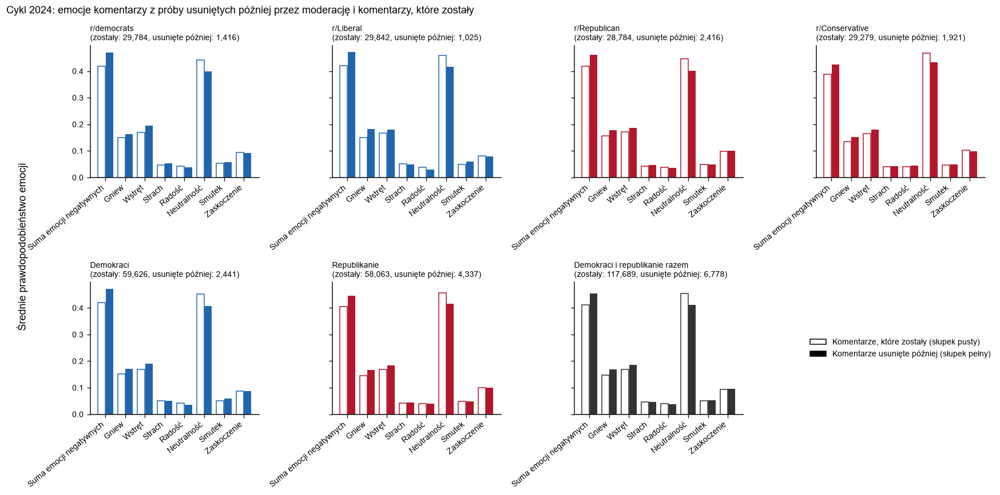

In [19]:
bar_columns = ["negative"] + EMOTIONS
positions = np.arange(len(bar_columns))
fig, axes = plt.subplots(2, 4, figsize=(16, 8), sharey=True)
for ax, group in zip(axes.flat, GROUPS):
    ax.bar(positions - 0.2, removed_means.loc[(group, False), bar_columns], width=0.38, color="white", edgecolor=GROUP_COLORS[group])
    ax.bar(positions + 0.2, removed_means.loc[(group, True), bar_columns], width=0.38, color=GROUP_COLORS[group])
    ax.set_xticks(positions, [EMOTION_LABELS[column] for column in bar_columns], rotation=40, ha="right")
    ax.set_title(f"{GROUP_LABELS[group]}\n(zostały: {removed_counts.loc[group, False]:,}, usunięte później: {removed_counts.loc[group, True]:,})",
                 loc="left", fontsize=9)
axes.flat[-1].axis("off")
axes.flat[-1].legend(handles=[Patch(facecolor="white", edgecolor="black", label="Komentarze, które zostały (słupek pusty)"),
                              Patch(color="black", label="Komentarze usunięte później (słupek pełny)")], loc="center")
fig.suptitle("Cykl 2024: emocje komentarzy z próby usuniętych później przez moderację i komentarzy, które zostały", x=0.01, ha="left",
             fontsize=12)
fig.supylabel("Średnie prawdopodobieństwo emocji")
plt.tight_layout()
plt.show()

**Jak czytać**
- Dotyczy tylko cyklu 2024, bo tylko tam dane mają pole removed_later: komentarz zarchiwizowany, zanim moderacja go usunęła (treść zachowana). Takie komentarze są w próbie.
- Dla każdej emocji dwa słupki: pusty to komentarze, które zostały, pełny to komentarze usunięte później. Słupek to średnie prawdopodobieństwo emocji. W tytule panelu są liczebności.

**Co widać**
- Komentarze usunięte później mają wyższą sumę emocji negatywnych: 0,454 wobec 0,412 (demokraci 0,471 wobec 0,420, republikanie 0,445 wobec 0,404). Kierunek jest ten sam w każdym z czterech subredditów.
- Różnica to gniew (0,169 wobec 0,148) i wstręt (0,186 wobec 0,169). Neutralność jest niższa (0,412 wobec 0,454). Radość, strach, smutek i zaskoczenie są prawie takie same.
- W próbie tych komentarzy jest 6 778 na 124 467 (ok. 5%). Obejmują one tylko komentarze zarchiwizowane przed usunięciem, więc nie reprezentują wszystkich usuniętych ([deleted] / [removed]).

## 14. H1 – faza bazowa i szczytowa oraz różnice względem bazowej

In [20]:
slopes = political_phases.pivot_table(index=["camp", "subreddit", "cycle"], columns="phase", values="negative")[["bazowa", "szczytowa"]]
later = political_diff[political_diff["phase"] != "bazowa"]
h1_summary = later.groupby("phase")["negative"].agg(["mean", "median", "min", "max"]).reindex(LATER_PHASES)
h1_summary["n_above_zero"] = (later["negative"] > 0).groupby(later["phase"]).sum()
h1_summary.round(4)

,mean,median,min,max,n_above_zero
phase,,,,,
przedwyborcza,-0.0019,-0.0039,-0.0148,0.0241,6
szczytowa,-0.0100,-0.0119,-0.0381,0.0445,5
przejsciowa,-0.0060,-0.0113,-0.0328,0.0337,5
powyborcza,-0.0001,-0.0019,-0.0182,0.0410,7


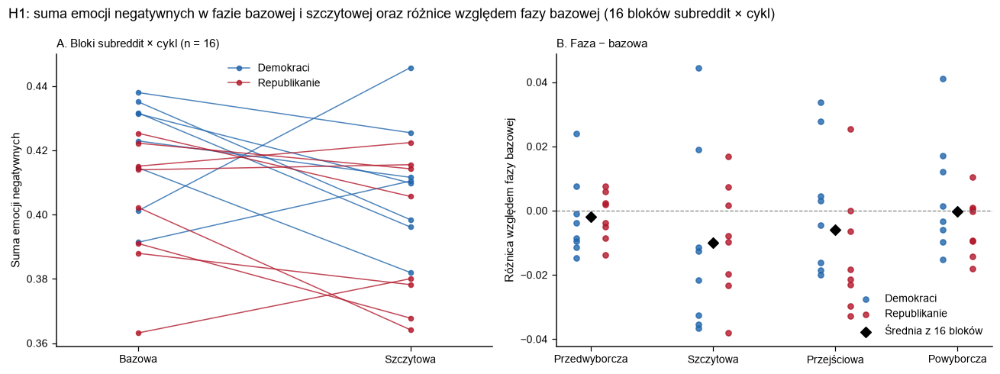

In [21]:
fig, axes = plt.subplots(1, 2, figsize=(12, 4.5))
for camp in ["dem", "rep"]:
    lines = axes[0].plot([0, 1], slopes.loc[camp].T.to_numpy(), color=CAMP_COLORS[camp], marker="o", markersize=4,
                         linewidth=1, alpha=0.8)
    lines[0].set_label(CAMP_LABELS[camp])
axes[0].set_xticks([0, 1], [PHASE_LABELS["bazowa"], PHASE_LABELS["szczytowa"]])
axes[0].set_xlim(-0.3, 1.3)
axes[0].set_ylabel("Suma emocji negatywnych")
axes[0].set_title("A. Bloki subreddit × cykl (n = 16)", loc="left")
axes[0].legend()
for position, phase in enumerate(LATER_PHASES):
    for offset, camp in ((-0.12, "dem"), (0.12, "rep")):
        values = later[(later["phase"] == phase) & (later["camp"] == camp)]["negative"]
        axes[1].scatter(np.full(len(values), position + offset), values, color=CAMP_COLORS[camp], s=22, alpha=0.8,
                        label=CAMP_LABELS[camp] if position == 0 else None)
    axes[1].scatter(position, h1_summary.loc[phase, "mean"], color="black", marker="D", s=40, zorder=3,
                    label="Średnia z 16 bloków" if position == 0 else None)
axes[1].axhline(0, color="0.5", linewidth=0.8, linestyle="--")
axes[1].set_xticks(range(len(LATER_PHASES)), PHASE_TICKS[1:])
axes[1].set_ylabel("Różnica względem fazy bazowej")
axes[1].set_title("B. Faza − bazowa", loc="left")
axes[1].legend(loc="lower right")
fig.suptitle("H1: suma emocji negatywnych w fazie bazowej i szczytowej oraz różnice względem fazy bazowej (16 bloków subreddit × cykl)", x=0.01, ha="left", fontsize=12)
plt.tight_layout()
plt.show()

**Jak czytać** (dwie figury: wszystkie bloki razem, potem osobno dla każdego cyklu)
- Blok to jeden subreddit w jednym cyklu (16 bloków). Panel A: linia łączy średnią sumę emocji negatywnych w fazie bazowej i szczytowej. Panel B: kropka to różnica faza minus bazowa, romb to średnia z bloków, linia kreskowana to brak zmiany.

**Co widać**
- Średnia różnica szczytowa − bazowa to −0,010 (mediana −0,012). Wyższa niż w bazie jest tylko w 5 z 16 bloków. Zakres od −0,038 do +0,045.
- Pozostałe fazy: przedwyborcza −0,002 (6 z 16 powyżej zera), przejściowa −0,006 (5 z 16), powyborcza 0,000 (7 z 16).

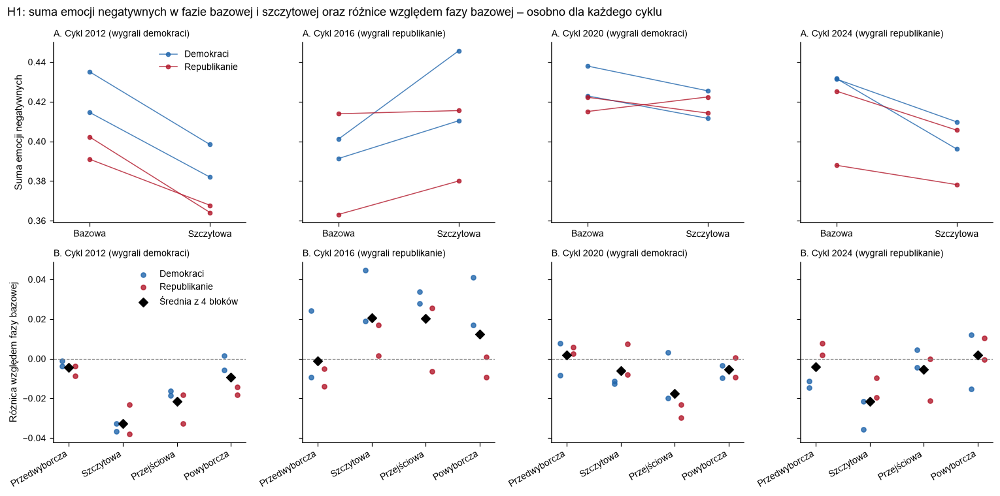

In [22]:
fig, axes = plt.subplots(2, len(CYCLES), figsize=(14, 7), sharey="row")
for column, cycle in enumerate(CYCLES):
    cycle_slopes = slopes.xs(cycle, level="cycle")
    for camp in ["dem", "rep"]:
        lines = axes[0, column].plot([0, 1], cycle_slopes.loc[camp].T.to_numpy(), color=CAMP_COLORS[camp], marker="o",
                                     markersize=4, linewidth=1, alpha=0.8)
        lines[0].set_label(CAMP_LABELS[camp])
    axes[0, column].set_xticks([0, 1], [PHASE_LABELS["bazowa"], PHASE_LABELS["szczytowa"]])
    axes[0, column].set_xlim(-0.3, 1.3)
    axes[0, column].set_title(f"A. Cykl {cycle} ({WINNER_LABELS[cycle]})", loc="left", fontsize=9)
    cycle_later = later[later["cycle"] == cycle]
    for position, phase in enumerate(LATER_PHASES):
        for offset, camp in ((-0.12, "dem"), (0.12, "rep")):
            values = cycle_later[(cycle_later["phase"] == phase) & (cycle_later["camp"] == camp)]["negative"]
            axes[1, column].scatter(np.full(len(values), position + offset), values, color=CAMP_COLORS[camp], s=22, alpha=0.8,
                                    label=CAMP_LABELS[camp] if position == 0 else None)
        axes[1, column].scatter(position, cycle_later[cycle_later["phase"] == phase]["negative"].mean(), color="black",
                                marker="D", s=40, zorder=3, label="Średnia z 4 bloków" if position == 0 else None)
    axes[1, column].axhline(0, color="0.5", linewidth=0.8, linestyle="--")
    axes[1, column].set_xticks(range(len(LATER_PHASES)), PHASE_TICKS[1:], rotation=30, ha="right")
    axes[1, column].set_title(f"B. Cykl {cycle} ({WINNER_LABELS[cycle]})", loc="left", fontsize=9)
axes[0, 0].set_ylabel("Suma emocji negatywnych")
axes[1, 0].set_ylabel("Różnica względem fazy bazowej")
axes[0, 0].legend()
axes[1, 0].legend(loc="upper right")
fig.suptitle("H1: suma emocji negatywnych w fazie bazowej i szczytowej oraz różnice względem fazy bazowej – osobno dla każdego cyklu", x=0.01, ha="left", fontsize=12)
plt.tight_layout()
plt.show()

**Jak czytać**
- Ten sam wykres co wyżej, osobno dla każdego cyklu (po 4 bloki). W nawiasie obóz, który wygrał wybory.

**Co widać**
- Znak zmiany zależy od cyklu. Szczytowa − bazowa (średnia z 4 bloków): 2012 −0,033, 2016 +0,021, 2020 −0,006, 2024 −0,022. Tylko w 2016 jest wzrost.
- W 2012 wszystkie cztery bloki spadają, ale baza trzech z czterech subredditów jest bardzo mała (mediana tygodnia w próbie: r/Liberal 26, r/democrats 31, r/Republican 55 komentarzy), więc ta zmiana jest najmniej pewna.
- Wielkości zmian (0,01–0,03) są porównywalne z rozrzutem pojedynczego tygodnia (sekcja 21), a w obrębie cyklu bloki idą często w różne strony.

## 15. H1 – subreddity polityczne a subreddity odniesienia

In [23]:
peak = diff[diff["phase"] == "szczytowa"].copy()
peak["group"] = np.where(peak["camp"] == "reference", "reference", "political")
specificity = peak.pivot_table(index="cycle", columns="group", values="negative", aggfunc="mean")
specificity["political_minus_reference"] = specificity["political"] - specificity["reference"]
specificity.to_csv(EDA_DIR / "emotions_peak_political_vs_reference.csv")
specificity.round(4)

group,political,reference,political_minus_reference
cycle,,,
2012,-0.0326,0.0041,-0.0367
2016,0.0205,-0.0001,0.0206
2020,-0.0061,-0.0065,0.0003
2024,-0.0216,0.0048,-0.0264


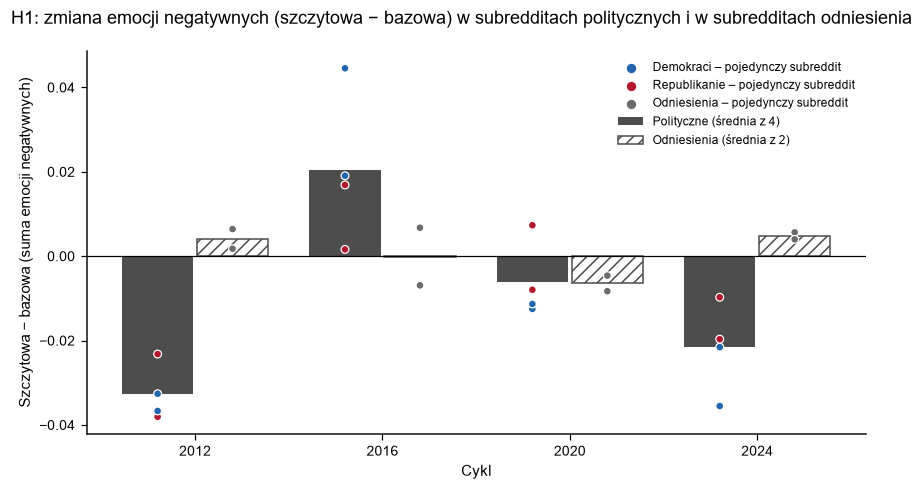

In [24]:
fig, ax = plt.subplots(figsize=(8, 4.5))
positions = np.arange(len(CYCLES))
ax.bar(positions - 0.2, specificity.loc[CYCLES, "political"], width=0.38, color="#4d4d4d", label="Polityczne (średnia z 4)")
ax.bar(positions + 0.2, specificity.loc[CYCLES, "reference"], width=0.38, color="white", edgecolor="#4d4d4d", hatch="///",
       label="Odniesienia (średnia z 2)")
for index, cycle in enumerate(CYCLES):
    for offset, group in ((-0.2, "political"), (0.2, "reference")):
        rows = peak[(peak["cycle"] == cycle) & (peak["group"] == group)]
        ax.scatter(np.full(len(rows), index + offset), rows["negative"], c=rows["camp"].map(CAMP_COLORS).tolist(), s=26,
                   edgecolor="white", linewidth=0.8, zorder=3)
for camp in ["dem", "rep", "reference"]:
    ax.scatter([], [], color=CAMP_COLORS[camp], s=26, label=f"{CAMP_LABELS[camp]} – pojedynczy subreddit")
ax.axhline(0, color="black", linewidth=0.8)
ax.set_xticks(positions, CYCLES)
ax.set_xlabel("Cykl")
ax.set_ylabel("Szczytowa − bazowa (suma emocji negatywnych)")
ax.legend(fontsize=8)
fig.suptitle("H1: zmiana emocji negatywnych (szczytowa − bazowa) w subredditach politycznych i w subredditach odniesienia", x=0.01, ha="left", fontsize=12)
plt.tight_layout()
plt.show()

**Jak czytać**
- Słupek pełny: średnia zmiana szczytowa − bazowa w sumie emocji negatywnych w czterech subredditach politycznych. Słupek kreskowany: ta sama zmiana w dwóch subredditach odniesienia (r/running, r/languagelearning) w tych samych tygodniach. Kropki to pojedyncze subreddity.

**Co widać**
- Odniesienia prawie się nie zmieniają: od −0,007 do +0,005 w każdym cyklu.
- Subreddity polityczne zmieniają się bardziej: −0,033 (2012), +0,021 (2016), −0,006 (2020), −0,022 (2024). Różnica polityczne − odniesienia: −0,037, +0,021, 0,000, −0,026. W 2012, 2016 i 2024 zmiana jest większa niż w odniesieniach, ale w różnych kierunkach, a w 2020 praktycznie jej nie ma.

## 16. H2 – wskaźnik pobudzenia i jego składniki

In [25]:
camp_arousal = political_phases.pivot_table(index="phase", columns="camp", values="arousal", aggfunc="mean").reindex(PHASE_ORDER)
components = political_phases.groupby("phase")[["anger", "fear", "sadness"]].mean().reindex(PHASE_ORDER)
pd.concat([camp_arousal.add_prefix("arousal_"), components], axis=1).round(4)

,arousal_dem,arousal_rep,anger,fear,sadness
phase,,,,,
bazowa,0.8012,0.8067,0.1533,0.0373,0.0464
przedwyborcza,0.8044,0.8053,0.1485,0.0414,0.0458
szczytowa,0.7923,0.8006,0.1421,0.0424,0.0469
przejsciowa,0.7939,0.8020,0.1497,0.0437,0.0491
powyborcza,0.8038,0.8046,0.1548,0.0425,0.0480


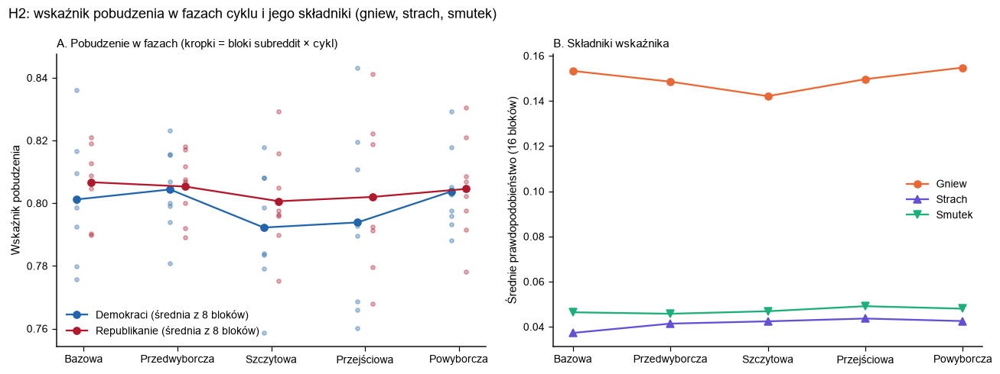

In [26]:
fig, axes = plt.subplots(1, 2, figsize=(12, 4.5))
for offset, camp in ((-0.08, "dem"), (0.08, "rep")):
    for position, phase in enumerate(PHASE_ORDER):
        values = political_phases[(political_phases["camp"] == camp) & (political_phases["phase"] == phase)]["arousal"]
        axes[0].scatter(np.full(len(values), position + offset), values, color=CAMP_COLORS[camp], s=12, alpha=0.35)
    axes[0].plot(PHASE_POSITIONS + offset, camp_arousal[camp], color=CAMP_COLORS[camp], marker="o", linewidth=1.5,
                 label=f"{CAMP_LABELS[camp]} (średnia z 8 bloków)")
axes[0].set_ylabel("Wskaźnik pobudzenia")
axes[0].set_title("A. Pobudzenie w fazach (kropki = bloki subreddit × cykl)", loc="left")
for emotion in ["anger", "fear", "sadness"]:
    color, linestyle, marker = EMOTION_STYLES[emotion]
    axes[1].plot(PHASE_POSITIONS, components[emotion], color=color, linestyle=linestyle, marker=marker, linewidth=1.5,
                 label=EMOTION_LABELS[emotion])
axes[1].set_ylabel("Średnie prawdopodobieństwo (16 bloków)")
axes[1].set_title("B. Składniki wskaźnika", loc="left")
for ax in axes:
    ax.set_xticks(PHASE_POSITIONS, PHASE_TICKS)
    ax.legend()
fig.suptitle("H2: wskaźnik pobudzenia w fazach cyklu i jego składniki (gniew, strach, smutek)", x=0.01, ha="left", fontsize=12)
plt.tight_layout()
plt.show()

**Jak czytać**
- Panel A: wskaźnik pobudzenia w kolejnych fazach, kropki to bloki subreddit × cykl, linie to średnie obozów (po 8 bloków). Panel B: średnie prawdopodobieństwo gniewu, strachu i smutku w fazach (średnia z 16 bloków).

**Co widać**
- Średnie obozów są prawie płaskie: demokraci 0,792–0,804, republikanie 0,801–0,807. Rozrzut kropek w obrębie fazy jest większy niż różnice między fazami.
- Składniki: gniew spada z 0,153 w bazie do 0,142 w fazie szczytowej, strach rośnie z 0,037 do 0,042, a smutek jest stały (0,046–0,049). W liczniku wskaźnika spadek gniewu częściowo równoważy wzrost strachu.

## 17. H3 – emocje negatywne względem fazy bazowej

In [27]:
h3 = political_diff.copy()
h3["result"] = np.where(h3["camp"] == h3["cycle"].map(WINNERS), "winner", "loser")
profile = h3.groupby("phase")["negative"].mean().reindex(PHASE_ORDER)
by_result = h3.pivot_table(index="phase", columns="result", values="negative", aggfunc="mean").reindex(PHASE_ORDER)
by_result.assign(all_blocks=profile).round(4)

result,loser,winner,all_blocks
phase,,,
bazowa,0.0000,0.0000,0.0000
przedwyborcza,-0.0020,-0.0019,-0.0019
szczytowa,-0.0069,-0.0130,-0.0100
przejsciowa,-0.0053,-0.0068,-0.0060
powyborcza,0.0017,-0.0020,-0.0001


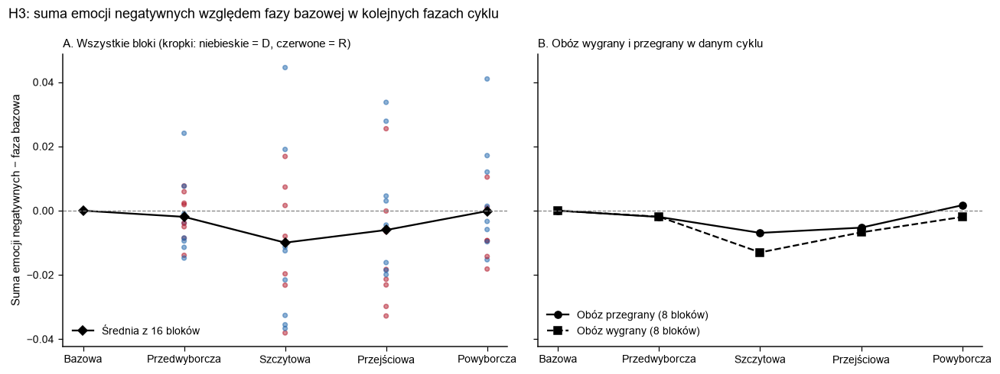

In [28]:
fig, axes = plt.subplots(1, 2, figsize=(12, 4.5), sharey=True)
for position, phase in enumerate(PHASE_ORDER):
    rows = h3[h3["phase"] == phase]
    axes[0].scatter(np.full(len(rows), position), rows["negative"], c=rows["camp"].map(CAMP_COLORS).tolist(), s=14, alpha=0.5)
axes[0].plot(PHASE_POSITIONS, profile, color="black", marker="D", linewidth=1.5, label="Średnia z 16 bloków")
axes[0].set_title("A. Wszystkie bloki (kropki: niebieskie = D, czerwone = R)", loc="left")
for result, linestyle, marker, label in (("loser", "-", "o", "Obóz przegrany (8 bloków)"),
                                         ("winner", "--", "s", "Obóz wygrany (8 bloków)")):
    axes[1].plot(PHASE_POSITIONS, by_result[result], color="black", linestyle=linestyle, marker=marker, linewidth=1.5,
                 label=label)
axes[1].set_title("B. Obóz wygrany i przegrany w danym cyklu", loc="left")
axes[0].set_ylabel("Suma emocji negatywnych − faza bazowa")
for ax in axes:
    ax.axhline(0, color="0.5", linewidth=0.8, linestyle="--")
    ax.set_xticks(PHASE_POSITIONS, PHASE_TICKS)
    ax.legend(loc="lower left")
fig.suptitle("H3: suma emocji negatywnych względem fazy bazowej w kolejnych fazach cyklu", x=0.01, ha="left", fontsize=12)
plt.tight_layout()
plt.show()

**Jak czytać**
- Wartość to suma emocji negatywnych minus faza bazowa (0 = poziom bazowy). Panel A: kropki to bloki (niebieskie demokraci, czerwone republikanie), romb to średnia z 16. Panel B: średnia osobno dla obozu, który wygrał wybory, i tego, który je przegrał (po 8 bloków).

**Co widać**
- Średnia: −0,002 (przedwyborcza), −0,010 (szczytowa), −0,006 (przejściowa), −0,000 (powyborcza). Po obniżeniu w fazie szczytowej wraca do poziomu bazowego w ostatniej fazie.
- Obóz wygrany: −0,013 w szczytowej i −0,002 w powyborczej. Obóz przegrany: −0,007 i +0,002. Różnice między obozami są mniejsze niż rozrzut bloków (kropki).

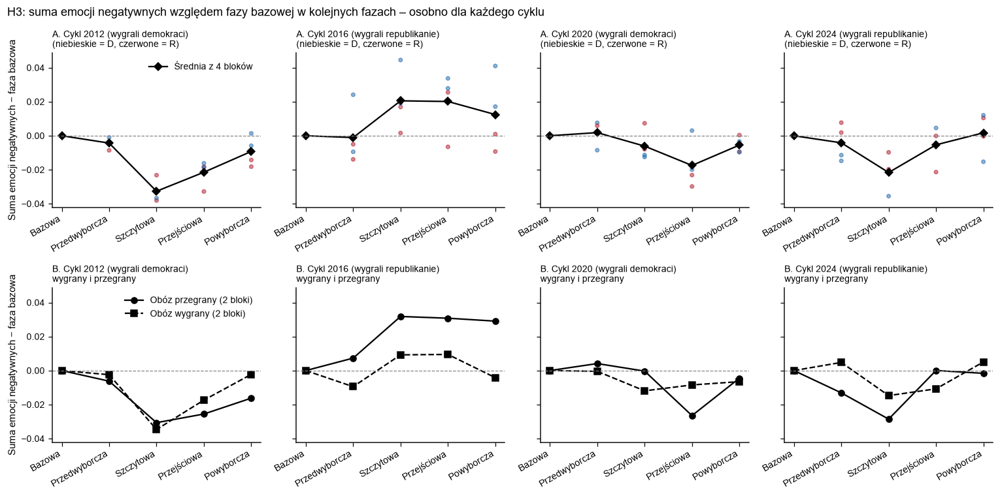

In [29]:
fig, axes = plt.subplots(2, len(CYCLES), figsize=(14, 7), sharey=True)
for column, cycle in enumerate(CYCLES):
    cycle_h3 = h3[h3["cycle"] == cycle]
    cycle_profile = cycle_h3.groupby("phase")["negative"].mean().reindex(PHASE_ORDER)
    cycle_by_result = cycle_h3.pivot_table(index="phase", columns="result", values="negative", aggfunc="mean").reindex(PHASE_ORDER)
    for position, phase in enumerate(PHASE_ORDER):
        rows = cycle_h3[cycle_h3["phase"] == phase]
        axes[0, column].scatter(np.full(len(rows), position), rows["negative"], c=rows["camp"].map(CAMP_COLORS).tolist(), s=14,
                                alpha=0.5)
    axes[0, column].plot(PHASE_POSITIONS, cycle_profile, color="black", marker="D", linewidth=1.5, label="Średnia z 4 bloków")
    axes[0, column].set_title(f"A. Cykl {cycle} ({WINNER_LABELS[cycle]})\n(niebieskie = D, czerwone = R)", loc="left", fontsize=9)
    for result, linestyle, marker, label in (("loser", "-", "o", "Obóz przegrany (2 bloki)"),
                                             ("winner", "--", "s", "Obóz wygrany (2 bloki)")):
        axes[1, column].plot(PHASE_POSITIONS, cycle_by_result[result], color="black", linestyle=linestyle, marker=marker,
                             linewidth=1.5, label=label)
    axes[1, column].set_title(f"B. Cykl {cycle} ({WINNER_LABELS[cycle]})\nwygrany i przegrany", loc="left", fontsize=9)
    for row in range(2):
        axes[row, column].axhline(0, color="0.5", linewidth=0.8, linestyle="--")
        axes[row, column].set_xticks(PHASE_POSITIONS, PHASE_TICKS, rotation=30, ha="right")
axes[0, 0].set_ylabel("Suma emocji negatywnych − faza bazowa")
axes[1, 0].set_ylabel("Suma emocji negatywnych − faza bazowa")
axes[0, 0].legend(loc="upper right")
axes[1, 0].legend(loc="upper right")
fig.suptitle("H3: suma emocji negatywnych względem fazy bazowej w kolejnych fazach – osobno dla każdego cyklu", x=0.01, ha="left", fontsize=12)
plt.tight_layout()
plt.show()

**Jak czytać**
- To samo co wyżej osobno dla każdego cyklu (górny wiersz: bloki i średnia z 4 bloków, dolny: obóz wygrany i przegrany, po 2 bloki).

**Co widać**
- Przebieg zależy od cyklu. Średnia różnica względem bazy w kolejnych fazach (przedwyborcza / szczytowa / przejściowa / powyborcza): 2012 −0,004 / −0,033 / −0,021 / −0,009, 2016 −0,001 / +0,021 / +0,020 / +0,012, 2020 +0,002 / −0,006 / −0,017 / −0,006, 2024 −0,004 / −0,022 / −0,005 / +0,002.
- W 2016 poziom pozostaje wyższy niż w bazie również po wyborach (+0,012). W 2012 i 2024 faza powyborcza jest bliżej bazy niż szczytowa (−0,009 i +0,002), w 2020 tak samo daleko (−0,006). Przy dwóch blokach na linię wyniki obozu wygranego i przegranego w pojedynczym cyklu są mało stabilne.

## 18. Składniki emocji negatywnych w fazach

In [30]:
components_diff = political_diff.groupby(["camp", "phase"])[NEGATIVE].mean()
components_diff.unstack("camp").reindex(LATER_PHASES).round(4)

anger         disgust            fear         sadness        
camp              dem     rep     dem     rep     dem     rep     dem     rep
phase                                                                        
przedwyborcza -0.0078 -0.0017  0.0028 -0.0041  0.0045  0.0038 -0.0017  0.0004
szczytowa     -0.0162 -0.0062 -0.0017 -0.0071  0.0067  0.0035  0.0003  0.0006
przejsciowa   -0.0033 -0.0040 -0.0055 -0.0174  0.0066  0.0062  0.0035  0.0019
powyborcza     0.0032 -0.0002 -0.0050 -0.0119  0.0050  0.0055  0.0015  0.0017

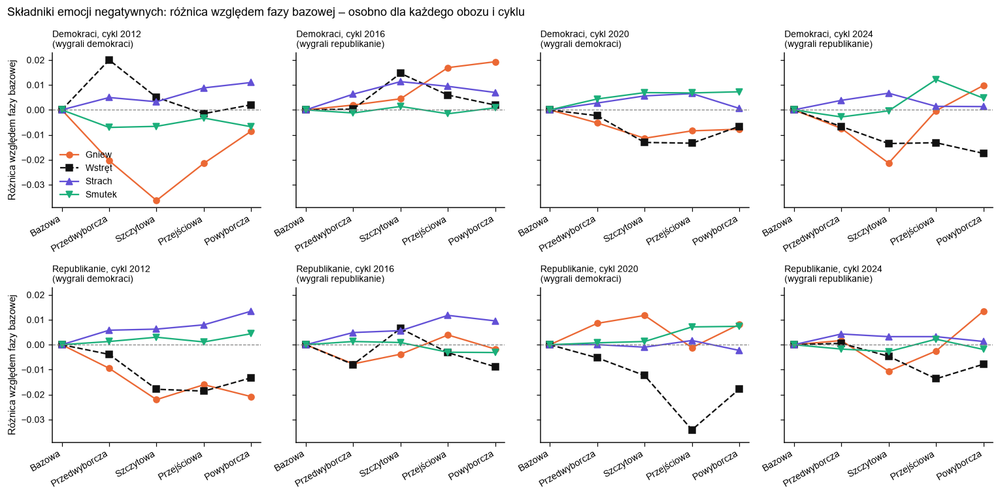

In [31]:
fig, axes = plt.subplots(2, len(CYCLES), figsize=(14, 7), sharey=True)
for column, cycle in enumerate(CYCLES):
    cycle_components = political_diff[political_diff["cycle"] == cycle].groupby(["camp", "phase"])[NEGATIVE].mean()
    for row, camp in enumerate(["dem", "rep"]):
        rows = cycle_components.loc[camp].reindex(PHASE_ORDER)
        for emotion in NEGATIVE:
            color, linestyle, marker = EMOTION_STYLES[emotion]
            axes[row, column].plot(PHASE_POSITIONS, rows[emotion], color=color, linestyle=linestyle, marker=marker, linewidth=1.5,
                                   label=EMOTION_LABELS[emotion])
        axes[row, column].axhline(0, color="0.5", linewidth=0.8, linestyle="--")
        axes[row, column].set_xticks(PHASE_POSITIONS, PHASE_TICKS, rotation=30, ha="right")
        axes[row, column].set_title(f"{CAMP_LABELS[camp]}, cykl {cycle}\n({WINNER_LABELS[cycle]})", loc="left", fontsize=9)
axes[0, 0].set_ylabel("Różnica względem fazy bazowej")
axes[1, 0].set_ylabel("Różnica względem fazy bazowej")
axes[0, 0].legend()
fig.suptitle("Składniki emocji negatywnych: różnica względem fazy bazowej – osobno dla każdego obozu i cyklu", x=0.01, ha="left", fontsize=12)
plt.tight_layout()
plt.show()

**Jak czytać**
- Wiersz to obóz, kolumna to cykl. Cztery linie to różnica względem fazy bazowej dla gniewu, wstrętu, strachu i smutku (każda w swoich kolorach). Linia kreskowana to brak zmiany. Każda linia to średnia z 2 subredditów obozu.

**Co widać**
- Zmiany pojedynczych emocji są małe (zwykle poniżej 0,02) i w większości cykli kierunek jest podobny: w fazie szczytowej gniew spada u demokratów w 2012, 2020 i 2024 (−0,036, −0,011, −0,021) i u republikanów w 2012 i 2024 (−0,022, −0,011), a w 2020 u republikanów rośnie (+0,012).
- Strach rośnie po fazie bazowej w prawie wszystkich komórkach (do +0,011), smutek prawie się nie zmienia (poniżej ±0,007).
- W obu obozach wstręt spada w 2020 i 2024 w fazie szczytowej, a w 2016 u demokratów rośnie (+0,015).
- Średnio (z 8 bloków na obóz) w fazie szczytowej gniew spada o 0,016 (demokraci) i 0,006 (republikanie), a wstręt u republikanów o 0,007 w szczytowej i 0,017 w przejściowej.

## 19. Radość, zaskoczenie i neutralność w fazach

In [32]:
others = diff.groupby(["camp", "phase"])[["joy", "surprise", "neutral"]].mean()
others.unstack("camp").reindex(LATER_PHASES).round(4)

joy                   surprise                   neutral  \
camp              dem reference     rep      dem reference     rep     dem   
phase                                                                        
przedwyborcza  0.0004    0.0048  0.0002   0.0052    0.0012 -0.0037 -0.0035   
szczytowa      0.0085    0.0031  0.0009   0.0113    0.0032  0.0030 -0.0089   
przejsciowa    0.0046    0.0079  0.0044   0.0008   -0.0002 -0.0020 -0.0067   
powyborcza     0.0004    0.0049  0.0016   0.0022    0.0005 -0.0021 -0.0073   

                                 
camp          reference     rep  
phase                            
przedwyborcza   -0.0031  0.0052  
szczytowa       -0.0068  0.0053  
przejsciowa     -0.0061  0.0109  
powyborcza      -0.0057  0.0055

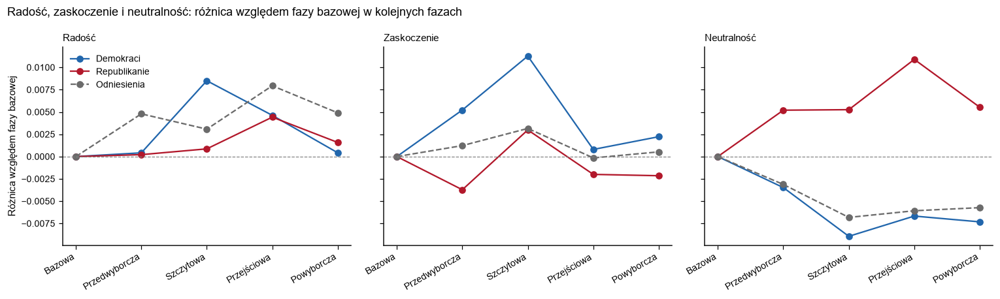

In [33]:
fig, axes = plt.subplots(1, 3, figsize=(14, 4.2), sharey=True)
for ax, emotion in zip(axes, ["joy", "surprise", "neutral"]):
    for camp in ["dem", "rep", "reference"]:
        rows = others.loc[camp].reindex(PHASE_ORDER)
        ax.plot(PHASE_POSITIONS, rows[emotion], color=CAMP_COLORS[camp], linestyle=CAMP_LINESTYLES[camp], marker="o",
                linewidth=1.5, label=CAMP_LABELS[camp])
    ax.axhline(0, color="0.5", linewidth=0.8, linestyle="--")
    ax.set_xticks(PHASE_POSITIONS, PHASE_TICKS, rotation=30, ha="right")
    ax.set_title(EMOTION_LABELS[emotion], loc="left")
axes[0].set_ylabel("Różnica względem fazy bazowej")
axes[0].legend()
fig.suptitle("Radość, zaskoczenie i neutralność: różnica względem fazy bazowej w kolejnych fazach", x=0.01, ha="left", fontsize=12)
plt.tight_layout()
plt.show()

**Jak czytać**
- Trzy panele: radość, zaskoczenie, neutralność. Linie to różnica względem fazy bazowej dla demokratów, republikanów i subredditów odniesienia (średnia ze wszystkich cykli).

**Co widać**
- W fazie szczytowej u demokratów rośnie radość (+0,009) i zaskoczenie (+0,011), a spada neutralność (−0,009). U republikanów radość i zaskoczenie prawie się nie zmieniają, a neutralność rośnie (+0,005).
- Neutralność spada też w odniesieniach (−0,007 w szczytowej), więc spadku u demokratów nie da się odnieść tylko do wyborów. Wszystkie zmiany są mniejsze niż 0,012.

## 20. Zmiana szczytowa − bazowa dla każdej emocji

In [34]:
peak_table = (diff[diff["phase"] == "szczytowa"].set_index(["subreddit", "cycle"])[EMOTIONS + ["negative"]]
              .reindex([(subreddit, cycle) for subreddit in SUBREDDITS for cycle in CYCLES]))
peak_table.to_csv(EDA_DIR / "emotions_peak_minus_baseline.csv")
peak_table.groupby(level="subreddit", sort=False).mean().round(3)

,anger,disgust,fear,joy,neutral,sadness,surprise,negative
subreddit,,,,,,,,
democrats,-0.018,-0.000,0.003,0.010,-0.006,-0.000,0.011,-0.015
Liberal,-0.014,-0.003,0.010,0.007,-0.012,0.001,0.011,-0.007
Republican,-0.008,-0.003,0.005,0.001,0.004,0.001,-0.001,-0.005
Conservative,-0.005,-0.011,0.002,0.000,0.006,-0.000,0.007,-0.014
running,-0.001,-0.004,0.003,0.007,-0.006,0.001,0.001,-0.001
languagelearning,-0.002,0.001,0.001,-0.001,-0.007,0.003,0.006,0.003


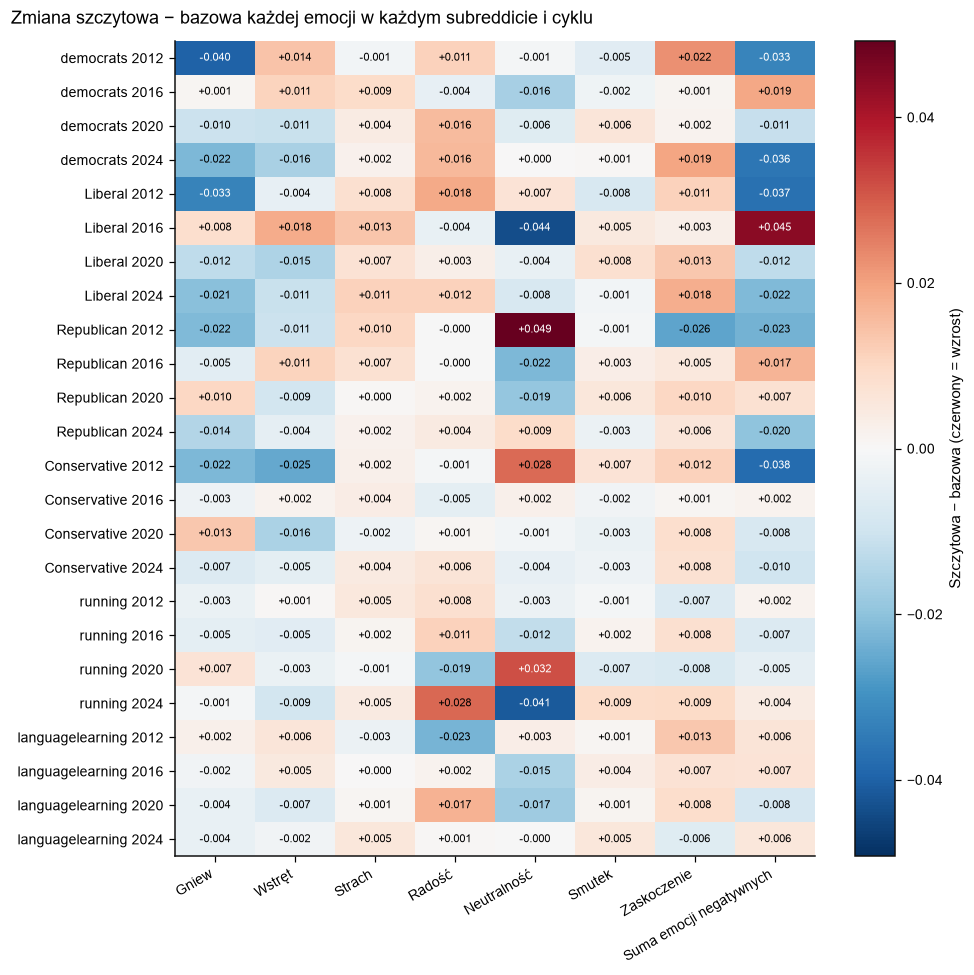

In [35]:
values = peak_table.to_numpy()
limit = np.nanmax(np.abs(values))
fig, ax = plt.subplots(figsize=(9, 9))
image = ax.imshow(values, cmap="RdBu_r", vmin=-limit, vmax=limit, aspect="auto")
ax.set_xticks(range(values.shape[1]), [EMOTION_LABELS[column] for column in peak_table.columns], rotation=30, ha="right")
ax.set_yticks(range(values.shape[0]), [f"{subreddit} {cycle}" for subreddit, cycle in peak_table.index])
for row in range(values.shape[0]):
    for column in range(values.shape[1]):
        ax.text(column, row, f"{values[row, column]:+.3f}", ha="center", va="center", fontsize=7,
                color="white" if abs(values[row, column]) > 0.6 * limit else "black")
fig.colorbar(image, ax=ax, label="Szczytowa − bazowa (czerwony = wzrost)")
fig.suptitle("Zmiana szczytowa − bazowa każdej emocji w każdym subreddicie i cyklu", x=0.01, ha="left", fontsize=12)
plt.tight_layout()
plt.show()

**Jak czytać**
- Wiersz to subreddit w jednym cyklu, kolumna to emocja. Liczba w komórce to różnica szczytowa − bazowa. Czerwony: wzrost, niebieski: spadek. Skala jest wspólna dla całej mapy.

**Co widać**
- Średnio według subredditu suma emocji negatywnych zmienia się o: r/democrats −0,015, r/Conservative −0,014, r/Liberal −0,007, r/Republican −0,005. W odniesieniach: r/running −0,001, r/languagelearning +0,003.
- W czterech subredditach politycznych średnio spada gniew (od −0,005 do −0,018) i rośnie strach (od +0,002 do +0,010).
- Największe pojedyncze zmiany to ok. ±0,04–0,05: m.in. neutralność w r/Republican 2012 (+0,049), suma negatywnych w r/Liberal 2016 (+0,045) i gniew w r/democrats 2012 (−0,040). Wiele z nich pochodzi z 2012, z małej bazy.

## 21. Szum tygodniowy a liczba komentarzy

In [36]:
noise = weekly.dropna(subset=["phase"]).copy()
noise["deviation"] = noise["negative"] - noise.groupby(["subreddit", "cycle", "phase"])["negative"].transform("mean")
noise["n_bin"] = pd.cut(noise["n"], bins=[0, 50, 150, MAX_PER_WEEK, MAX_PER_WEEK + 1], right=False,
                        labels=["< 50", "50–149", f"150–{MAX_PER_WEEK - 1}", str(MAX_PER_WEEK)])
noise_by_bin = noise.groupby("n_bin", observed=False)["deviation"].agg(n_weeks="size", sd="std")
noise_by_block = noise.groupby(["camp", "subreddit", "cycle"]).agg(median_n=("n", "median"), sd_deviation=("deviation", "std"))
noise_by_block.to_csv(EDA_DIR / "emotions_weekly_noise.csv")
noise_by_bin.round(4)

,n_weeks,sd
n_bin,,
< 50,41,0.0735
50–149,129,0.0438
150–299,194,0.0317
300,2443,0.0253


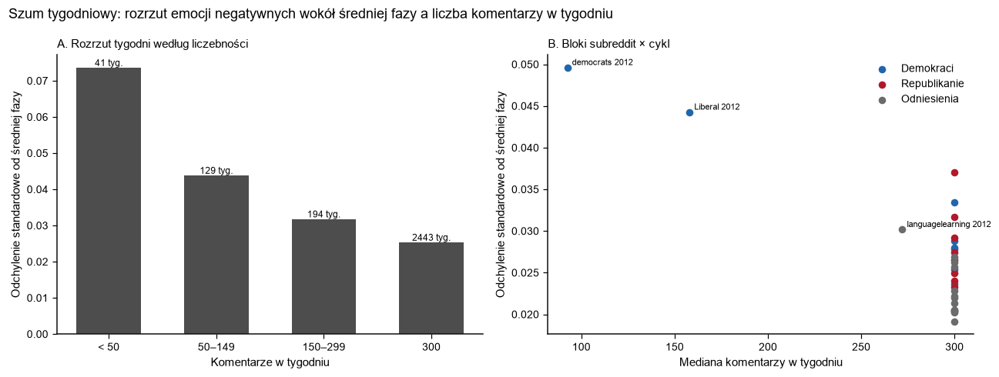

In [37]:
fig, axes = plt.subplots(1, 2, figsize=(12, 4.5))
axes[0].bar(range(len(noise_by_bin)), noise_by_bin["sd"], color="#4d4d4d", width=0.6)
for index, (label, row) in enumerate(noise_by_bin.iterrows()):
    axes[0].text(index, row["sd"], f"{int(row['n_weeks'])} tyg.", ha="center", va="bottom", fontsize=8)
axes[0].set_xticks(range(len(noise_by_bin)), noise_by_bin.index)
axes[0].set_xlabel("Komentarze w tygodniu")
axes[0].set_ylabel("Odchylenie standardowe od średniej fazy")
axes[0].set_title("A. Rozrzut tygodni według liczebności", loc="left")
blocks = noise_by_block.reset_index()
for camp in ["dem", "rep", "reference"]:
    rows = blocks[blocks["camp"] == camp]
    axes[1].scatter(rows["median_n"], rows["sd_deviation"], color=CAMP_COLORS[camp], s=28, label=CAMP_LABELS[camp])
for _, row in blocks[blocks["median_n"] < MAX_PER_WEEK].iterrows():
    axes[1].annotate(f"{row['subreddit']} {row['cycle']}", (row["median_n"], row["sd_deviation"]), fontsize=7,
                     xytext=(4, 2), textcoords="offset points")
axes[1].set_xlabel("Mediana komentarzy w tygodniu")
axes[1].set_ylabel("Odchylenie standardowe od średniej fazy")
axes[1].set_title("B. Bloki subreddit × cykl", loc="left")
axes[1].legend()
fig.suptitle("Szum tygodniowy: rozrzut emocji negatywnych wokół średniej fazy a liczba komentarzy w tygodniu", x=0.01, ha="left", fontsize=12)
plt.tight_layout()
plt.show()

**Jak czytać**
- Panel A: odchylenie standardowe tygodniowej sumy emocji negatywnych od średniej swojej fazy, w grupach według liczby komentarzy w próbie tego tygodnia (nad słupkiem liczba tygodni). Panel B: każdy punkt to blok subreddit × cykl, oś X to mediana komentarzy w tygodniu, oś Y to to samo odchylenie. Opisane są tylko bloki z medianą poniżej 300.

**Co widać**
- Rozrzut maleje z liczebnością: 0,074 przy mniej niż 50 komentarzach (41 tygodni), 0,044 przy 50–149, 0,032 przy 150–299 i 0,025 przy pełnych 300 (2 443 tygodnie).
- Różnice faza − bazowa rzędu 0,01 są więc mniejsze niż rozrzut jednego typowego tygodnia (0,025), a średnia z wielu tygodni jest dokładniejsza niż pojedynczy tydzień. Bloki z małą próbą (głównie 2012) są mniej dokładne.

## 22. Wrażliwość na próg 10 słów

In [38]:
in_cycle_10w = phases_10w[phases_10w["phase"].isin(PHASE_ORDER)]
baseline_10w = in_cycle_10w[in_cycle_10w["phase"] == "bazowa"].set_index(["subreddit", "cycle"])[MEASURES]
diff_10w = in_cycle_10w.join(baseline_10w, on=["subreddit", "cycle"], rsuffix="_baseline")
for measure in MEASURES:
    diff_10w[measure] = diff_10w[measure] - diff_10w[f"{measure}_baseline"]
sensitivity = diff.merge(diff_10w[["subreddit", "cycle", "phase", "negative", "arousal"]], on=["subreddit", "cycle", "phase"],
                         suffixes=("_all", "_10w"))
sensitivity = sensitivity[sensitivity["phase"] != "bazowa"]
sensitivity.to_csv(EDA_DIR / "emotions_sensitivity_10w.csv", index=False)
sensitivity.groupby("phase")[["negative_all", "negative_10w", "arousal_all", "arousal_10w"]].mean().reindex(LATER_PHASES).round(4)

,negative_all,negative_10w,arousal_all,arousal_10w
phase,,,,
przedwyborcza,-0.0023,-0.0012,-0.0043,-0.0053
szczytowa,-0.0064,-0.0072,-0.0081,-0.0084
przejsciowa,-0.0046,-0.0038,-0.0091,-0.0118
powyborcza,0.0000,0.0021,-0.0081,-0.0099


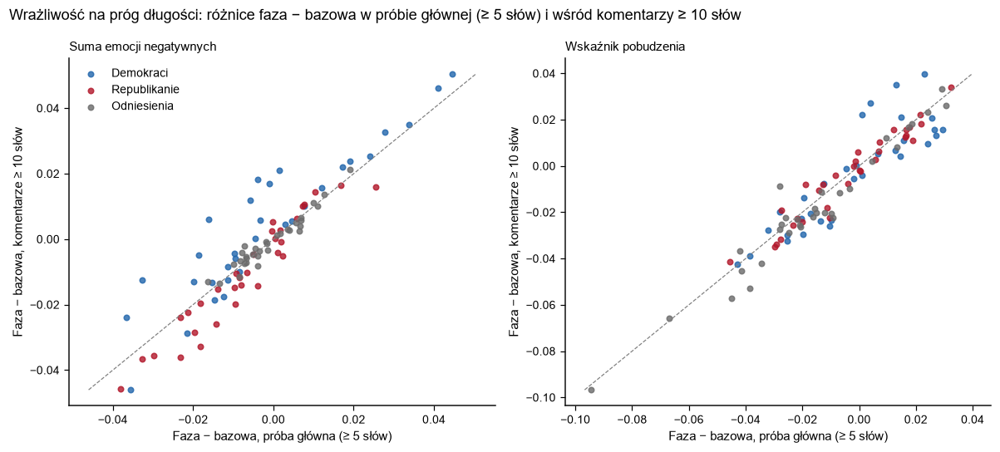

In [39]:
fig, axes = plt.subplots(1, 2, figsize=(11, 5))
for ax, measure in zip(axes, ["negative", "arousal"]):
    for camp in ["dem", "rep", "reference"]:
        rows = sensitivity[sensitivity["camp"] == camp]
        ax.scatter(rows[f"{measure}_all"], rows[f"{measure}_10w"], color=CAMP_COLORS[camp], s=18, alpha=0.8,
                   label=CAMP_LABELS[camp])
    low = sensitivity[[f"{measure}_all", f"{measure}_10w"]].min().min()
    high = sensitivity[[f"{measure}_all", f"{measure}_10w"]].max().max()
    ax.plot([low, high], [low, high], color="0.5", linewidth=0.8, linestyle="--")
    ax.set_xlabel("Faza − bazowa, próba główna (≥ 5 słów)")
    ax.set_ylabel("Faza − bazowa, komentarze ≥ 10 słów")
    ax.set_title(EMOTION_LABELS[measure], loc="left")
axes[0].legend()
fig.suptitle("Wrażliwość na próg długości: różnice faza − bazowa w próbie głównej (≥ 5 słów) i wśród komentarzy ≥ 10 słów", x=0.01, ha="left", fontsize=12)
plt.tight_layout()
plt.show()

**Jak czytać**
- Punkt to jedna komórka subreddit × cykl × faza (bez bazowej). Oś X: różnica faza − bazowa w próbie głównej (komentarze od 5 słów), oś Y: ta sama różnica tylko dla komentarzy od 10 słów. Linia przerywana to zgodność (y = x).

**Co widać**
- Punkty leżą blisko przekątnej: korelacja 0,92 dla sumy emocji negatywnych i 0,95 dla pobudzenia.
- Średnie według fazy zmieniają się niewiele: szczytowa −0,0064 wobec −0,0072, przejściowa −0,0046 wobec −0,0038, powyborcza 0,000 wobec +0,002. Próg długości prawie nie zmienia wzorca.

## 23. Sezonowość w subredditach odniesienia

In [40]:
reference = weekly[weekly["camp"] == "reference"].copy()
thursday = reference["week_start"] + pd.Timedelta(days=3)
reference["year"] = thursday.dt.year
reference["week_of_year"] = thursday.dt.isocalendar().week.astype(int)
reference = reference[reference["year"].isin(CYCLES + REFERENCE_YEARS) & (reference["week_of_year"] <= 52)]  # tydzień 53 jest tylko w 2020
reference["election_year"] = reference["year"].isin(CYCLES)
seasonal = reference.groupby(["subreddit", "election_year", "week_of_year"], as_index=False)["negative"].mean()
seasonal["smoothed"] = (seasonal.groupby(["subreddit", "election_year"])["negative"]
                        .transform(lambda values: values.rolling(SMOOTH_WEEKS, center=True, min_periods=1).mean()))
election_weeks_of_year = sorted({pd.Timestamp(day).isocalendar().week for day in ELECTION_DAYS.values()})
reference.pivot_table(index="subreddit", columns="year", values="n", aggfunc="size")

year,2012,2014,2016,2018,2020,2022,2024
subreddit,,,,,,,
languagelearning,52,52,52,52,52,52,52
running,52,52,52,52,52,52,52


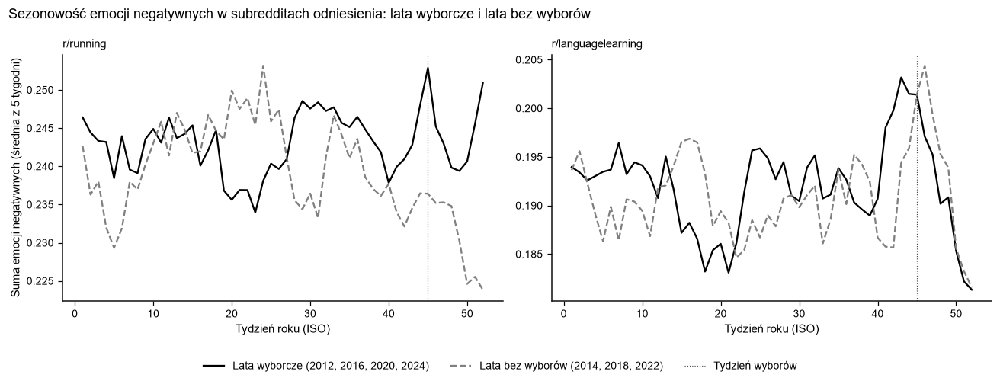

In [41]:
fig, axes = plt.subplots(1, 2, figsize=(12, 4.5))
for ax, subreddit in zip(axes, REFERENCE_SUBREDDITS):
    for election_year, color, linestyle, label in ((True, "black", "-", f"Lata wyborcze ({', '.join(map(str, CYCLES))})"),
                                                   (False, "0.5", "--", f"Lata bez wyborów ({', '.join(map(str, REFERENCE_YEARS))})")):
        rows = seasonal[(seasonal["subreddit"] == subreddit) & (seasonal["election_year"] == election_year)]
        ax.plot(rows["week_of_year"], rows["smoothed"], color=color, linestyle=linestyle, linewidth=1.5, label=label)
    for week in election_weeks_of_year:
        ax.axvline(week, color="0.3", linewidth=0.8, linestyle=":", label="Tydzień wyborów")
    ax.set_xlabel("Tydzień roku (ISO)")
    ax.set_title(f"r/{subreddit}", loc="left")
axes[0].set_ylabel(f"Suma emocji negatywnych (średnia z {SMOOTH_WEEKS} tygodni)")
fig.legend(*axes[0].get_legend_handles_labels(), loc="lower center", ncol=3)
fig.suptitle("Sezonowość emocji negatywnych w subredditach odniesienia: lata wyborcze i lata bez wyborów", x=0.01, ha="left", fontsize=12)
plt.tight_layout(rect=(0, 0.08, 1, 1))
plt.show()

**Jak czytać**
- Oś X: tydzień roku (ISO). Linia ciągła: średnia z lat wyborczych (2012, 2016, 2020, 2024), szara przerywana: średnia z lat bez wyborów (2014, 2018, 2022), obie wygładzone średnią z 5 tygodni. Pionowa kropkowana linia: tydzień wyborów.

**Co widać**
- Poziom jest stały: r/running ok. 0,24, r/languagelearning ok. 0,19, a linie z lat wyborczych i bez wyborów różnią się średnio o +0,004 i +0,001. Odchylenie standardowe sezonowego profilu to 0,010–0,014, a największa różnica między liniami w jednym tygodniu roku (bez wygładzania) to ok. ±0,045.
- W r/running linia lat wyborczych ma lokalny szczyt w tygodniu wyborów (0,253), a w latach bez wyborów jest tam niżej (0,236). W r/languagelearning oba profile mają jesienny szczyt w tygodniach 43–46 (ok. 0,203–0,205) i spadek pod koniec roku. Profil to średnia z kilku lat, więc pojedyncze różnice nie muszą być stałe.